In [1]:

# ==================================================
# Step 6.3.1 - Part A
# SaaS Business Performance Analysis
# Notebook Setup and Data Loading
# ==================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path

# Define project root
project_root = Path.cwd().parent

# Define monthly KPI dataset path
kpi_file_path = (
    project_root
    / "data"
    / "processed"
    / "SaaS_Monthly_KPI_Summary.csv"
)

# Verify dataset exists
assert kpi_file_path.is_file(), (
    f"Monthly KPI dataset not found: {kpi_file_path}"
)

# Load dataset
performance_df = pd.read_csv(kpi_file_path)

# Convert Month to datetime
performance_df["Month"] = pd.to_datetime(
    performance_df["Month"],
    errors="coerce"
)

# Sort chronologically
performance_df = (
    performance_df
    .sort_values("Month")
    .reset_index(drop=True)
)

# Validate dataset
assert not performance_df.empty, (
    "Performance dataset is empty."
)

assert performance_df["Month"].notna().all(), (
    "Invalid reporting months detected."
)

assert performance_df["Month"].is_unique, (
    "Duplicate reporting months detected."
)

# Required business performance metrics
required_columns = [
    "Month",
    "Total_MRR_USD",
    "MRR_Growth_Pct",
    "New_MRR",
    "Expansion_MRR",
    "Contraction_MRR",
    "Churn_MRR",
    "Subscription_Churn_Rate_Pct",
    "Subscription_Retention_Rate_Pct",
    "Customer_Retention_Rate_Pct",
    "GRR_Pct",
    "NRR_Pct"
]

missing_columns = [
    col for col in required_columns
    if col not in performance_df.columns
]

assert not missing_columns, (
    f"Missing required columns: {missing_columns}"
)

# Convert metric columns to numeric
numeric_columns = [
    col for col in required_columns
    if col != "Month"
]

performance_df[numeric_columns] = (
    performance_df[numeric_columns]
    .apply(pd.to_numeric, errors="coerce")
)

# Verify numeric metrics
assert performance_df["Total_MRR_USD"].notna().all(), (
    "Missing Total MRR values detected."
)

print("========== BUSINESS PERFORMANCE DATA LOADING ==========")

print("Dataset Loaded: PASS")
print("Total Reporting Months:", len(performance_df))
print("Total Columns:", len(performance_df.columns))

print(
    "Reporting Period:",
    performance_df["Month"].min().strftime("%b %Y"),
    "to",
    performance_df["Month"].max().strftime("%b %Y")
)

print("Required KPI Columns: PASS")
print("Month Validation: PASS")

print("=======================================================")

display(performance_df[required_columns].head())


========== BUSINESS PERFORMANCE DATA LOADING ==========
Dataset Loaded: PASS
Total Reporting Months: 30
Total Columns: 25
Reporting Period: Jan 2024 to Jun 2026
Required KPI Columns: PASS
Month Validation: PASS


,Month,Total_MRR_USD,MRR_Growth_Pct,New_MRR,Expansion_MRR,Contraction_MRR,Churn_MRR,Subscription_Churn_Rate_Pct,Subscription_Retention_Rate_Pct,Customer_Retention_Rate_Pct,GRR_Pct,NRR_Pct
0,2024-01-01,145853.24,NaN,145853.24,0.00,-0.0,-0.00,NaN,NaN,NaN,NaN,NaN
1,2024-02-01,151051.80,3.56,6830.65,1276.20,615.4,2292.89,2.80,97.20,97.20,98.01,98.88
2,2024-03-01,155769.21,3.12,2047.34,5748.80,279.4,2799.33,2.99,97.01,97.01,97.96,101.77
3,2024-04-01,163530.40,4.98,5965.74,4819.65,375.2,2649.00,2.59,97.41,97.41,98.06,101.15
4,2024-05-01,171524.29,4.89,3828.17,6698.50,204.0,2328.78,2.58,97.42,97.42,98.45,102.55


In [2]:

# ==================================================
# Step 6.3.1 - Part B
# Business Performance KPI Data Quality Validation
# ==================================================

import pandas as pd
import numpy as np

# Work with the dataset loaded in Part A
kpi_validation_df = performance_df.copy()

# -----------------------------------------------
# 1. Check duplicate and missing reporting months
# -----------------------------------------------

duplicate_months = (
    kpi_validation_df["Month"].duplicated().sum()
)

missing_months = (
    kpi_validation_df["Month"].isna().sum()
)

# -----------------------------------------------
# 2. Check required KPI missing values
# -----------------------------------------------

required_kpis = [
    "Total_MRR_USD",
    "MRR_Growth_Pct",
    "New_MRR",
    "Expansion_MRR",
    "Contraction_MRR",
    "Churn_MRR",
    "Subscription_Churn_Rate_Pct",
    "Subscription_Retention_Rate_Pct",
    "Customer_Retention_Rate_Pct",
    "GRR_Pct",
    "NRR_Pct"
]

missing_kpi_summary = (
    kpi_validation_df[required_kpis]
    .isna()
    .sum()
)

# -----------------------------------------------
# 3. Validate non-negative revenue components
# -----------------------------------------------

revenue_columns = [
    "Total_MRR_USD",
    "New_MRR",
    "Expansion_MRR",
    "Contraction_MRR",
    "Churn_MRR"
]

negative_revenue_counts = (
    kpi_validation_df[revenue_columns] < 0
).sum()

# -----------------------------------------------
# 4. Validate percentage KPI ranges
# -----------------------------------------------

bounded_percentage_columns = [
    "Subscription_Churn_Rate_Pct",
    "Subscription_Retention_Rate_Pct",
    "Customer_Retention_Rate_Pct",
    "GRR_Pct"
]

invalid_percentage_counts = {}

for col in bounded_percentage_columns:

    invalid_percentage_counts[col] = int(
        (
            (kpi_validation_df[col] < 0)
            | (kpi_validation_df[col] > 100)
        ).sum()
    )

# NRR can legitimately exceed 100% due to expansion
invalid_nrr_count = int(
    (kpi_validation_df["NRR_Pct"] < 0).sum()
)

# MRR growth can be negative or exceed 100%
# so we do not impose a 0-100% range on it.

# -----------------------------------------------
# 5. Validate monthly reporting continuity
# -----------------------------------------------

actual_months = pd.PeriodIndex(
    kpi_validation_df["Month"],
    freq="M"
)

expected_months = pd.period_range(
    start=actual_months.min(),
    end=actual_months.max(),
    freq="M"
)

missing_reporting_periods = (
    expected_months.difference(actual_months)
)

# -----------------------------------------------
# 6. Check numerical infinity values
# -----------------------------------------------

infinite_value_counts = {}

for col in required_kpis:

    infinite_value_counts[col] = int(
        np.isinf(
            kpi_validation_df[col].to_numpy(
                dtype=float
            )
        ).sum()
    )

# -----------------------------------------------
# 7. Display validation results
# -----------------------------------------------

print("========== BUSINESS KPI DATA QUALITY ==========")

print("Total Reporting Months:", len(kpi_validation_df))
print("Duplicate Months:", duplicate_months)
print("Missing Month Values:", missing_months)

print(
    "Missing Reporting Periods:",
    len(missing_reporting_periods)
)

print("\nMissing KPI Values:")
print(missing_kpi_summary.to_string())

print("\nNegative Revenue Values:")
print(negative_revenue_counts.to_string())

print("\nInvalid Percentage Values:")
for metric, count in invalid_percentage_counts.items():
    print(f"{metric}: {count}")

print("Negative NRR Values:", invalid_nrr_count)

print("\nInfinite KPI Values:")
for metric, count in infinite_value_counts.items():
    print(f"{metric}: {count}")

# -----------------------------------------------
# 8. Overall validation result
# -----------------------------------------------

# First month's growth can be undefined because
# there may be no previous reporting month.
growth_missing = missing_kpi_summary[
    "MRR_Growth_Pct"
]

other_missing = missing_kpi_summary.drop(
    "MRR_Growth_Pct"
).sum()

growth_missing_valid = (
    growth_missing == 0
    or (
        growth_missing == 1
        and pd.isna(
            kpi_validation_df.iloc[0]["MRR_Growth_Pct"]
        )
    )
)

validation_passed = all([
    duplicate_months == 0,
    missing_months == 0,
    len(missing_reporting_periods) == 0,
    other_missing == 0,
    growth_missing_valid,
    negative_revenue_counts.sum() == 0,
    sum(invalid_percentage_counts.values()) == 0,
    invalid_nrr_count == 0,
    sum(infinite_value_counts.values()) == 0
])

print("\nOVERALL KPI DATA QUALITY STATUS:",
      "PASS" if validation_passed else "REVIEW REQUIRED")

print("===============================================")


========== BUSINESS KPI DATA QUALITY ==========
Total Reporting Months: 30
Duplicate Months: 0
Missing Month Values: 0
Missing Reporting Periods: 0

Missing KPI Values:
Total_MRR_USD                      0
MRR_Growth_Pct                     1
New_MRR                            0
Expansion_MRR                      0
Contraction_MRR                    0
Churn_MRR                          0
Subscription_Churn_Rate_Pct        1
Subscription_Retention_Rate_Pct    1
Customer_Retention_Rate_Pct        1
GRR_Pct                            1
NRR_Pct                            1

Negative Revenue Values:
Total_MRR_USD      0
New_MRR            0
Expansion_MRR      0
Contraction_MRR    0
Churn_MRR          0

Invalid Percentage Values:
Subscription_Churn_Rate_Pct: 0
Subscription_Retention_Rate_Pct: 0
Customer_Retention_Rate_Pct: 0
GRR_Pct: 0
Negative NRR Values: 0

Infinite KPI Values:
Total_MRR_USD: 0
MRR_Growth_Pct: 0
New_MRR: 0
Expansion_MRR: 0
Contraction_MRR: 0
Churn_MRR: 0
Subscription_Chur

In [3]:

# ==================================================
# Step 6.3.1 - Part C
# Prepare SaaS Business Performance Analysis Dataset
# ==================================================

import pandas as pd
import numpy as np

# -----------------------------------------------
# 1. Select required business performance columns
# -----------------------------------------------

performance_columns = [
    "Month",
    "Total_MRR_USD",
    "Previous_Month_MRR",
    "MRR_Change_USD",
    "MRR_Growth_Pct",
    "New_MRR",
    "Expansion_MRR",
    "Contraction_MRR",
    "Churn_MRR",
    "Reactivation_MRR",
    "Net_MRR_Change",
    "Opening_Paid_Subscriptions",
    "Churn_Records",
    "Subscription_Churn_Rate_Pct",
    "Subscription_Retention_Rate_Pct",
    "Opening_Paid_Customers",
    "Retained_Customers",
    "Closing_Paid_Customers",
    "Customer_Retention_Rate_Pct",
    "Opening_MRR_USD",
    "GRR_Pct",
    "NRR_Pct"
]

# Verify all required columns exist
missing_columns = [
    col for col in performance_columns
    if col not in performance_df.columns
]

assert not missing_columns, (
    f"Missing columns: {missing_columns}"
)

# Create analysis-ready DataFrame
business_performance = (
    performance_df[performance_columns]
    .copy()
    .sort_values("Month")
    .reset_index(drop=True)
)

# -----------------------------------------------
# 2. Convert columns to appropriate data types
# -----------------------------------------------

business_performance["Month"] = pd.to_datetime(
    business_performance["Month"],
    errors="coerce"
)

numeric_columns = [
    col for col in business_performance.columns
    if col != "Month"
]

business_performance[numeric_columns] = (
    business_performance[numeric_columns]
    .apply(pd.to_numeric, errors="coerce")
)

# -----------------------------------------------
# 3. Add reporting period fields
# -----------------------------------------------

business_performance["Year"] = (
    business_performance["Month"].dt.year
)

business_performance["Month_Name"] = (
    business_performance["Month"].dt.strftime("%b")
)

business_performance["Year_Month"] = (
    business_performance["Month"].dt.strftime("%Y-%m")
)

# -----------------------------------------------
# 4. Add revenue performance indicators
# -----------------------------------------------

business_performance["MRR_Growth_Status"] = np.select(
    [
        business_performance["MRR_Growth_Pct"] > 0,
        business_performance["MRR_Growth_Pct"] < 0,
        business_performance["MRR_Growth_Pct"] == 0
    ],
    [
        "Positive Growth",
        "Negative Growth",
        "No Growth"
    ],
    default="Not Available"
)

business_performance["NRR_Status"] = np.select(
    [
        business_performance["NRR_Pct"] > 100,
        business_performance["NRR_Pct"] < 100,
        business_performance["NRR_Pct"] == 100
    ],
    [
        "Net Expansion",
        "Net Revenue Loss",
        "Fully Retained"
    ],
    default="Not Available"
)

# -----------------------------------------------
# 5. Validate prepared dataset
# -----------------------------------------------

assert not business_performance.empty, (
    "Business performance dataset is empty."
)

assert business_performance["Month"].notna().all(), (
    "Invalid reporting months detected."
)

assert business_performance["Month"].is_unique, (
    "Duplicate reporting months detected."
)

assert len(business_performance) == len(performance_df), (
    "Row count mismatch after preparation."
)

assert business_performance[
    "Total_MRR_USD"
].notna().all(), (
    "Missing Total MRR values detected."
)

# -----------------------------------------------
# 6. Display final dataset summary
# -----------------------------------------------

print("========== BUSINESS PERFORMANCE DATA PREPARATION ==========")

print("Dataset Preparation: PASS")

print("Total Reporting Months:", len(business_performance))
print("Total Columns:", len(business_performance.columns))

print(
    "Reporting Period:",
    business_performance["Month"].min().strftime("%b %Y"),
    "to",
    business_performance["Month"].max().strftime("%b %Y")
)

print("\nMRR Growth Status Distribution:")
print(
    business_performance[
        "MRR_Growth_Status"
    ].value_counts().to_string()
)

print("\nNRR Status Distribution:")
print(
    business_performance[
        "NRR_Status"
    ].value_counts().to_string()
)

print("\nFinal Dataset Validation: PASS")

print("===========================================================")

display(business_performance.head())


========== BUSINESS PERFORMANCE DATA PREPARATION ==========
Dataset Preparation: PASS
Total Reporting Months: 30
Total Columns: 27
Reporting Period: Jan 2024 to Jun 2026

MRR Growth Status Distribution:
MRR_Growth_Status
Positive Growth    29
Not Available       1

NRR Status Distribution:
NRR_Status
Net Expansion       22
Net Revenue Loss     7
Not Available        1

Final Dataset Validation: PASS


,Month,Total_MRR_USD,Previous_Month_MRR,MRR_Change_USD,MRR_Growth_Pct,New_MRR,Expansion_MRR,Contraction_MRR,Churn_MRR,Reactivation_MRR,...,Closing_Paid_Customers,Customer_Retention_Rate_Pct,Opening_MRR_USD,GRR_Pct,NRR_Pct,Year,Month_Name,Year_Month,MRR_Growth_Status,NRR_Status
0,2024-01-01,145853.24,NaN,NaN,NaN,145853.24,0.00,-0.0,-0.00,0.0,...,464,NaN,0.00,NaN,NaN,2024,Jan,2024-01,Not Available,Not Available
1,2024-02-01,151051.80,145853.24,5198.56,3.56,6830.65,1276.20,615.4,2292.89,0.0,...,468,97.20,145853.24,98.01,98.88,2024,Feb,2024-02,Positive Growth,Net Revenue Loss
2,2024-03-01,155769.21,151051.80,4717.41,3.12,2047.34,5748.80,279.4,2799.33,0.0,...,463,97.01,151051.80,97.96,101.77,2024,Mar,2024-03,Positive Growth,Net Expansion
3,2024-04-01,163530.40,155769.21,7761.19,4.98,5965.74,4819.65,375.2,2649.00,0.0,...,465,97.41,155769.21,98.06,101.15,2024,Apr,2024-04,Positive Growth,Net Expansion
4,2024-05-01,171524.29,163530.40,7993.89,4.89,3828.17,6698.50,204.0,2328.78,0.0,...,474,97.42,163530.40,98.45,102.55,2024,May,2024-05,Positive Growth,Net Expansion


In [8]:

# ==================================================
# Step 6.3.2 - Part A (Corrected)
# Revenue Growth and Retention Data Validation
# ==================================================

import pandas as pd
import numpy as np

# 1. Select required columns
analysis_columns = [
    "Month",
    "Year_Month",
    "Total_MRR_USD",
    "MRR_Growth_Pct",
    "Subscription_Churn_Rate_Pct",
    "Subscription_Retention_Rate_Pct",
    "Customer_Retention_Rate_Pct",
    "GRR_Pct",
    "NRR_Pct",
    "MRR_Growth_Status",
    "NRR_Status"
]

growth_retention_df = (
    business_performance[analysis_columns]
    .copy()
    .sort_values("Month")
    .reset_index(drop=True)
)

# 2. Convert numeric columns
numeric_metrics = [
    "Total_MRR_USD",
    "MRR_Growth_Pct",
    "Subscription_Churn_Rate_Pct",
    "Subscription_Retention_Rate_Pct",
    "Customer_Retention_Rate_Pct",
    "GRR_Pct",
    "NRR_Pct"
]

growth_retention_df[numeric_metrics] = (
    growth_retention_df[numeric_metrics]
    .apply(pd.to_numeric, errors="coerce")
)

# 3. Check revenue values
assert growth_retention_df["Total_MRR_USD"].notna().all(), (
    "Missing MRR values detected."
)

# 4. Check missing retention metrics
retention_metrics = [
    "Subscription_Churn_Rate_Pct",
    "Subscription_Retention_Rate_Pct",
    "Customer_Retention_Rate_Pct",
    "GRR_Pct",
    "NRR_Pct"
]

# Missing retention values are allowed only in
# the first reporting month, subject to opening
# denominator checks below.
assert growth_retention_df[
    retention_metrics
].iloc[1:].notna().all().all(), (
    "Missing retention KPI values after first month."
)

# 5. Verify first-month missing KPI denominators
first_month = business_performance.sort_values(
    "Month"
).iloc[0]

denominator_mapping = {
    "Subscription_Churn_Rate_Pct":
        "Opening_Paid_Subscriptions",
    "Subscription_Retention_Rate_Pct":
        "Opening_Paid_Subscriptions",
    "Customer_Retention_Rate_Pct":
        "Opening_Paid_Customers",
    "GRR_Pct":
        "Opening_MRR_USD",
    "NRR_Pct":
        "Opening_MRR_USD"
}

for metric, denominator in denominator_mapping.items():

    if pd.isna(growth_retention_df.iloc[0][metric]):

        opening_value = first_month[denominator]

        assert pd.notna(opening_value) and opening_value == 0, (
            f"{metric} is missing but "
            f"{denominator} is not zero: {opening_value}"
        )

# 6. Validate numeric infinity values
assert not np.isinf(
    growth_retention_df[numeric_metrics].to_numpy(
        dtype=float
    )
).any(), "Infinite KPI values detected."

# 7. Validate percentage ranges
bounded_metrics = [
    "Subscription_Churn_Rate_Pct",
    "Subscription_Retention_Rate_Pct",
    "Customer_Retention_Rate_Pct",
    "GRR_Pct"
]

for metric in bounded_metrics:

    valid_values = growth_retention_df[metric].dropna()

    assert valid_values.between(0, 100).all(), (
        f"Invalid percentage values in {metric}"
    )

assert (
    growth_retention_df["NRR_Pct"]
    .dropna()
    .ge(0)
    .all()
), "Negative NRR detected."

# 8. Identify months with valid growth and retention
growth_retention_df["Growth_Data_Available"] = (
    growth_retention_df["MRR_Growth_Pct"].notna()
)

growth_retention_df["Retention_Data_Available"] = (
    growth_retention_df[retention_metrics]
    .notna()
    .all(axis=1)
)

valid_growth_retention = (
    growth_retention_df[
        growth_retention_df["Growth_Data_Available"]
        & growth_retention_df["Retention_Data_Available"]
    ]
    .copy()
    .reset_index(drop=True)
)

# 9. Display results
print("========== GROWTH & RETENTION VALIDATION ==========")

print("Total Months:", len(growth_retention_df))

print(
    "Months With Complete Growth and Retention:",
    len(valid_growth_retention)
)

print(
    "Months With Missing Retention:",
    (~growth_retention_df["Retention_Data_Available"]).sum()
)

print(
    "First Month Opening Subscriptions:",
    first_month["Opening_Paid_Subscriptions"]
)

print(
    "First Month Opening Customers:",
    first_month["Opening_Paid_Customers"]
)

print(
    "First Month Opening MRR:",
    first_month["Opening_MRR_USD"]
)

print("Retention Validation: PASS")
print("Overall Analysis Data Validation: PASS")

print("===================================================")

display(
    growth_retention_df[
        [
            "Year_Month",
            "MRR_Growth_Pct",
            "Customer_Retention_Rate_Pct",
            "GRR_Pct",
            "NRR_Pct",
            "Growth_Data_Available",
            "Retention_Data_Available"
        ]
    ].head(10)
)


========== GROWTH & RETENTION VALIDATION ==========
Total Months: 30
Months With Complete Growth and Retention: 29
Months With Missing Retention: 1
First Month Opening Subscriptions: 0
First Month Opening Customers: 0
First Month Opening MRR: 0.0
Retention Validation: PASS
Overall Analysis Data Validation: PASS


,Year_Month,MRR_Growth_Pct,Customer_Retention_Rate_Pct,GRR_Pct,NRR_Pct,Growth_Data_Available,Retention_Data_Available
0,2024-01,NaN,NaN,NaN,NaN,False,False
1,2024-02,3.56,97.20,98.01,98.88,True,True
2,2024-03,3.12,97.01,97.96,101.77,True,True
3,2024-04,4.98,97.41,98.06,101.15,True,True
4,2024-05,4.89,97.42,98.45,102.55,True,True
5,2024-06,3.26,98.10,99.05,100.76,True,True
6,2024-07,4.64,98.12,99.19,102.91,True,True
7,2024-08,3.95,98.35,99.32,102.19,True,True
8,2024-09,4.42,97.17,98.42,100.16,True,True
9,2024-10,2.84,97.25,97.49,99.16,True,True


In [9]:

# ==================================================
# Step 6.3.2 - Part A (Corrected)
# Revenue Growth and Retention Data Validation
# ==================================================

import pandas as pd
import numpy as np

# 1. Select required columns
analysis_columns = [
    "Month",
    "Year_Month",
    "Total_MRR_USD",
    "MRR_Growth_Pct",
    "Subscription_Churn_Rate_Pct",
    "Subscription_Retention_Rate_Pct",
    "Customer_Retention_Rate_Pct",
    "GRR_Pct",
    "NRR_Pct",
    "MRR_Growth_Status",
    "NRR_Status"
]

growth_retention_df = (
    business_performance[analysis_columns]
    .copy()
    .sort_values("Month")
    .reset_index(drop=True)
)

# 2. Convert numeric columns
numeric_metrics = [
    "Total_MRR_USD",
    "MRR_Growth_Pct",
    "Subscription_Churn_Rate_Pct",
    "Subscription_Retention_Rate_Pct",
    "Customer_Retention_Rate_Pct",
    "GRR_Pct",
    "NRR_Pct"
]

growth_retention_df[numeric_metrics] = (
    growth_retention_df[numeric_metrics]
    .apply(pd.to_numeric, errors="coerce")
)

# 3. Check revenue values
assert growth_retention_df["Total_MRR_USD"].notna().all(), (
    "Missing MRR values detected."
)

# 4. Check missing retention metrics
retention_metrics = [
    "Subscription_Churn_Rate_Pct",
    "Subscription_Retention_Rate_Pct",
    "Customer_Retention_Rate_Pct",
    "GRR_Pct",
    "NRR_Pct"
]

# Missing retention values are allowed only in
# the first reporting month, subject to opening
# denominator checks below.
assert growth_retention_df[
    retention_metrics
].iloc[1:].notna().all().all(), (
    "Missing retention KPI values after first month."
)

# 5. Verify first-month missing KPI denominators
first_month = business_performance.sort_values(
    "Month"
).iloc[0]

denominator_mapping = {
    "Subscription_Churn_Rate_Pct":
        "Opening_Paid_Subscriptions",
    "Subscription_Retention_Rate_Pct":
        "Opening_Paid_Subscriptions",
    "Customer_Retention_Rate_Pct":
        "Opening_Paid_Customers",
    "GRR_Pct":
        "Opening_MRR_USD",
    "NRR_Pct":
        "Opening_MRR_USD"
}

for metric, denominator in denominator_mapping.items():

    if pd.isna(growth_retention_df.iloc[0][metric]):

        opening_value = first_month[denominator]

        assert pd.notna(opening_value) and opening_value == 0, (
            f"{metric} is missing but "
            f"{denominator} is not zero: {opening_value}"
        )

# 6. Validate numeric infinity values
assert not np.isinf(
    growth_retention_df[numeric_metrics].to_numpy(
        dtype=float
    )
).any(), "Infinite KPI values detected."

# 7. Validate percentage ranges
bounded_metrics = [
    "Subscription_Churn_Rate_Pct",
    "Subscription_Retention_Rate_Pct",
    "Customer_Retention_Rate_Pct",
    "GRR_Pct"
]

for metric in bounded_metrics:

    valid_values = growth_retention_df[metric].dropna()

    assert valid_values.between(0, 100).all(), (
        f"Invalid percentage values in {metric}"
    )

assert (
    growth_retention_df["NRR_Pct"]
    .dropna()
    .ge(0)
    .all()
), "Negative NRR detected."

# 8. Identify months with valid growth and retention
growth_retention_df["Growth_Data_Available"] = (
    growth_retention_df["MRR_Growth_Pct"].notna()
)

growth_retention_df["Retention_Data_Available"] = (
    growth_retention_df[retention_metrics]
    .notna()
    .all(axis=1)
)

valid_growth_retention = (
    growth_retention_df[
        growth_retention_df["Growth_Data_Available"]
        & growth_retention_df["Retention_Data_Available"]
    ]
    .copy()
    .reset_index(drop=True)
)

# 9. Display results
print("========== GROWTH & RETENTION VALIDATION ==========")

print("Total Months:", len(growth_retention_df))

print(
    "Months With Complete Growth and Retention:",
    len(valid_growth_retention)
)

print(
    "Months With Missing Retention:",
    (~growth_retention_df["Retention_Data_Available"]).sum()
)

print(
    "First Month Opening Subscriptions:",
    first_month["Opening_Paid_Subscriptions"]
)

print(
    "First Month Opening Customers:",
    first_month["Opening_Paid_Customers"]
)

print(
    "First Month Opening MRR:",
    first_month["Opening_MRR_USD"]
)

print("Retention Validation: PASS")
print("Overall Analysis Data Validation: PASS")

print("===================================================")

display(
    growth_retention_df[
        [
            "Year_Month",
            "MRR_Growth_Pct",
            "Customer_Retention_Rate_Pct",
            "GRR_Pct",
            "NRR_Pct",
            "Growth_Data_Available",
            "Retention_Data_Available"
        ]
    ].head(10)
)


========== GROWTH & RETENTION VALIDATION ==========
Total Months: 30
Months With Complete Growth and Retention: 29
Months With Missing Retention: 1
First Month Opening Subscriptions: 0
First Month Opening Customers: 0
First Month Opening MRR: 0.0
Retention Validation: PASS
Overall Analysis Data Validation: PASS


,Year_Month,MRR_Growth_Pct,Customer_Retention_Rate_Pct,GRR_Pct,NRR_Pct,Growth_Data_Available,Retention_Data_Available
0,2024-01,NaN,NaN,NaN,NaN,False,False
1,2024-02,3.56,97.20,98.01,98.88,True,True
2,2024-03,3.12,97.01,97.96,101.77,True,True
3,2024-04,4.98,97.41,98.06,101.15,True,True
4,2024-05,4.89,97.42,98.45,102.55,True,True
5,2024-06,3.26,98.10,99.05,100.76,True,True
6,2024-07,4.64,98.12,99.19,102.91,True,True
7,2024-08,3.95,98.35,99.32,102.19,True,True
8,2024-09,4.42,97.17,98.42,100.16,True,True
9,2024-10,2.84,97.25,97.49,99.16,True,True


========== MISSING KPI DIAGNOSIS ==========

Missing Values by KPI:
Total_MRR_USD                      0
Subscription_Churn_Rate_Pct        1
Subscription_Retention_Rate_Pct    1
Customer_Retention_Rate_Pct        1
GRR_Pct                            1
NRR_Pct                            1

Total Months With Missing KPI Values: 1

Affected Months and KPI Values:


,Year_Month,Total_MRR_USD,Subscription_Churn_Rate_Pct,Subscription_Retention_Rate_Pct,Customer_Retention_Rate_Pct,GRR_Pct,NRR_Pct
0,2024-01,145853.24,NaN,NaN,NaN,NaN,NaN



Columns Requiring Investigation:
Subscription_Churn_Rate_Pct        1
Subscription_Retention_Rate_Pct    1
Customer_Retention_Rate_Pct        1
GRR_Pct                            1
NRR_Pct                            1


In [10]:

# ==========================================================
# STEP 6.3.2 - PART A
# REVENUE GROWTH & RETENTION ANALYSIS
# Complete Corrected Code
# ==========================================================

import pandas as pd
import numpy as np

# ----------------------------------------------------------
# 1. Select Required Analysis Columns
# ----------------------------------------------------------

analysis_columns = [
    "Month",
    "Year_Month",
    "Total_MRR_USD",
    "MRR_Growth_Pct",
    "Subscription_Churn_Rate_Pct",
    "Subscription_Retention_Rate_Pct",
    "Customer_Retention_Rate_Pct",
    "GRR_Pct",
    "NRR_Pct",
    "MRR_Growth_Status",
    "NRR_Status"
]

missing_columns = [
    col for col in analysis_columns
    if col not in business_performance.columns
]

assert not missing_columns, (
    f"Missing analysis columns: {missing_columns}"
)

# ----------------------------------------------------------
# 2. Create Revenue Growth & Retention DataFrame
# ----------------------------------------------------------

growth_retention_df = (
    business_performance[analysis_columns]
    .copy()
    .sort_values("Month")
    .reset_index(drop=True)
)

# ----------------------------------------------------------
# 3. Convert Numeric Metrics
# ----------------------------------------------------------

numeric_metrics = [
    "Total_MRR_USD",
    "MRR_Growth_Pct",
    "Subscription_Churn_Rate_Pct",
    "Subscription_Retention_Rate_Pct",
    "Customer_Retention_Rate_Pct",
    "GRR_Pct",
    "NRR_Pct"
]

growth_retention_df[numeric_metrics] = (
    growth_retention_df[numeric_metrics]
    .apply(pd.to_numeric, errors="coerce")
)

# ----------------------------------------------------------
# 4. Validate Revenue Data
# ----------------------------------------------------------

assert not growth_retention_df.empty, (
    "Analysis dataset is empty."
)

assert growth_retention_df["Total_MRR_USD"].notna().all(), (
    "Missing Total MRR values detected."
)

assert (
    growth_retention_df["Total_MRR_USD"] >= 0
).all(), "Negative MRR values detected."

# ----------------------------------------------------------
# 5. Identify Retention Metrics
# ----------------------------------------------------------

retention_metrics = [
    "Subscription_Churn_Rate_Pct",
    "Subscription_Retention_Rate_Pct",
    "Customer_Retention_Rate_Pct",
    "GRR_Pct",
    "NRR_Pct"
]

# January 2024 may have undefined retention metrics
# because opening customer, subscription and MRR
# denominators may be zero.

# Check missing values after the first reporting month

assert growth_retention_df[
    retention_metrics
].iloc[1:].notna().all().all(), (
    "Missing retention values found after first month."
)

# ----------------------------------------------------------
# 6. Validate First-Month Missing Retention Metrics
# ----------------------------------------------------------

first_month = (
    business_performance
    .sort_values("Month")
    .iloc[0]
)

denominator_mapping = {
    "Subscription_Churn_Rate_Pct":
        "Opening_Paid_Subscriptions",

    "Subscription_Retention_Rate_Pct":
        "Opening_Paid_Subscriptions",

    "Customer_Retention_Rate_Pct":
        "Opening_Paid_Customers",

    "GRR_Pct":
        "Opening_MRR_USD",

    "NRR_Pct":
        "Opening_MRR_USD"
}

print("========== FIRST MONTH RETENTION CHECK ==========")

print(
    "First Reporting Month:",
    first_month["Month"].strftime("%b %Y")
)

print(
    "Opening Paid Subscriptions:",
    first_month["Opening_Paid_Subscriptions"]
)

print(
    "Opening Paid Customers:",
    first_month["Opening_Paid_Customers"]
)

print(
    "Opening MRR:",
    first_month["Opening_MRR_USD"]
)

for metric, denominator in denominator_mapping.items():

    if pd.isna(growth_retention_df.iloc[0][metric]):

        opening_value = first_month[denominator]

        assert pd.notna(opening_value) and opening_value == 0, (
            f"{metric} is missing, but "
            f"{denominator} = {opening_value}"
        )

print("First Month Retention Validation: PASS")

print("=================================================")

# ----------------------------------------------------------
# 7. Validate Infinite Values
# ----------------------------------------------------------

assert not np.isinf(
    growth_retention_df[numeric_metrics]
    .to_numpy(dtype=float)
).any(), (
    "Infinite KPI values detected."
)

# ----------------------------------------------------------
# 8. Validate Percentage Ranges
# ----------------------------------------------------------

bounded_metrics = [
    "Subscription_Churn_Rate_Pct",
    "Subscription_Retention_Rate_Pct",
    "Customer_Retention_Rate_Pct",
    "GRR_Pct"
]

for metric in bounded_metrics:

    valid_values = (
        growth_retention_df[metric].dropna()
    )

    assert valid_values.between(0, 100).all(), (
        f"Invalid percentage values in {metric}"
    )

# NRR can exceed 100% due to expansion
assert (
    growth_retention_df["NRR_Pct"]
    .dropna()
    .ge(0)
    .all()
), "Negative NRR values detected."

# ----------------------------------------------------------
# 9. Identify Available Growth and Retention Data
# ----------------------------------------------------------

growth_retention_df["Growth_Data_Available"] = (
    growth_retention_df["MRR_Growth_Pct"].notna()
)

growth_retention_df["Retention_Data_Available"] = (
    growth_retention_df[retention_metrics]
    .notna()
    .all(axis=1)
)

# Select months where both growth and retention
# metrics are available

valid_growth_retention = (
    growth_retention_df[
        growth_retention_df["Growth_Data_Available"]
        & growth_retention_df["Retention_Data_Available"]
    ]
    .copy()
    .reset_index(drop=True)
)

# ----------------------------------------------------------
# 10. Validate Reporting Months
# ----------------------------------------------------------

assert growth_retention_df["Month"].notna().all(), (
    "Invalid reporting months detected."
)

assert growth_retention_df["Month"].is_unique, (
    "Duplicate reporting months detected."
)

assert len(growth_retention_df) == len(
    business_performance
), "Reporting month count mismatch."

# ----------------------------------------------------------
# 11. Display Final Validation Summary
# ----------------------------------------------------------

print("\n========== GROWTH & RETENTION DATA VALIDATION ==========")

print(
    "Total Reporting Months:",
    len(growth_retention_df)
)

print(
    "Months With Valid Growth Data:",
    growth_retention_df["Growth_Data_Available"].sum()
)

print(
    "Months With Valid Retention Data:",
    growth_retention_df["Retention_Data_Available"].sum()
)

print(
    "Months With Complete Growth and Retention Data:",
    len(valid_growth_retention)
)

print(
    "Months With Missing Retention:",
    (~growth_retention_df["Retention_Data_Available"]).sum()
)

print("Revenue Data Validation: PASS")
print("Retention Percentage Validation: PASS")
print("NRR Validation: PASS")
print("Overall Analysis Data Validation: PASS")

print("========================================================")

# ----------------------------------------------------------
# 12. Display Final Analysis DataFrame
# ----------------------------------------------------------

display(
    growth_retention_df[
        [
            "Year_Month",
            "Total_MRR_USD",
            "MRR_Growth_Pct",
            "Subscription_Churn_Rate_Pct",
            "Subscription_Retention_Rate_Pct",
            "Customer_Retention_Rate_Pct",
            "GRR_Pct",
            "NRR_Pct",
            "Growth_Data_Available",
            "Retention_Data_Available"
        ]
    ].head(10)
)


========== FIRST MONTH RETENTION CHECK ==========
First Reporting Month: Jan 2024
Opening Paid Subscriptions: 0
Opening Paid Customers: 0
Opening MRR: 0.0
First Month Retention Validation: PASS

========== GROWTH & RETENTION DATA VALIDATION ==========
Total Reporting Months: 30
Months With Valid Growth Data: 29
Months With Valid Retention Data: 29
Months With Complete Growth and Retention Data: 29
Months With Missing Retention: 1
Revenue Data Validation: PASS
Retention Percentage Validation: PASS
NRR Validation: PASS
Overall Analysis Data Validation: PASS


,Year_Month,Total_MRR_USD,MRR_Growth_Pct,Subscription_Churn_Rate_Pct,Subscription_Retention_Rate_Pct,Customer_Retention_Rate_Pct,GRR_Pct,NRR_Pct,Growth_Data_Available,Retention_Data_Available
0,2024-01,145853.24,NaN,NaN,NaN,NaN,NaN,NaN,False,False
1,2024-02,151051.80,3.56,2.80,97.20,97.20,98.01,98.88,True,True
2,2024-03,155769.21,3.12,2.99,97.01,97.01,97.96,101.77,True,True
3,2024-04,163530.40,4.98,2.59,97.41,97.41,98.06,101.15,True,True
4,2024-05,171524.29,4.89,2.58,97.42,97.42,98.45,102.55,True,True
5,2024-06,177113.30,3.26,1.90,98.10,98.10,99.05,100.76,True,True
6,2024-07,185335.76,4.64,1.88,98.12,98.12,99.19,102.91,True,True
7,2024-08,192664.71,3.95,1.65,98.35,98.35,99.32,102.19,True,True
8,2024-09,201173.32,4.42,2.83,97.17,97.17,98.42,100.16,True,True
9,2024-10,206885.58,2.84,2.75,97.25,97.25,97.49,99.16,True,True


In [11]:

# ==========================================================
# STEP 6.3.2 - PART B
# REVENUE GROWTH & RETENTION BUSINESS INSIGHTS
# ==========================================================

import pandas as pd
import numpy as np

# ----------------------------------------------------------
# 1. Validate analysis-ready data
# ----------------------------------------------------------

assert not growth_retention_df.empty, (
    "Growth and retention dataset is empty."
)

assert not valid_growth_retention.empty, (
    "No months with complete growth and retention data."
)

# January 2024 has undefined retention percentages.
# Use only valid months for comparative analysis.
analysis_df = valid_growth_retention.copy()

# ----------------------------------------------------------
# 2. Revenue growth insights
# ----------------------------------------------------------

average_mrr_growth = (
    analysis_df["MRR_Growth_Pct"].mean()
)

median_mrr_growth = (
    analysis_df["MRR_Growth_Pct"].median()
)

positive_growth_months = int(
    (analysis_df["MRR_Growth_Pct"] > 0).sum()
)

negative_growth_months = int(
    (analysis_df["MRR_Growth_Pct"] < 0).sum()
)

zero_growth_months = int(
    (analysis_df["MRR_Growth_Pct"] == 0).sum()
)

highest_growth_month = analysis_df.loc[
    analysis_df["MRR_Growth_Pct"].idxmax()
]

lowest_growth_month = analysis_df.loc[
    analysis_df["MRR_Growth_Pct"].idxmin()
]

# ----------------------------------------------------------
# 3. Customer and subscription retention insights
# ----------------------------------------------------------

average_customer_retention = (
    analysis_df["Customer_Retention_Rate_Pct"].mean()
)

average_subscription_retention = (
    analysis_df["Subscription_Retention_Rate_Pct"].mean()
)

average_subscription_churn = (
    analysis_df["Subscription_Churn_Rate_Pct"].mean()
)

highest_customer_retention_month = analysis_df.loc[
    analysis_df["Customer_Retention_Rate_Pct"].idxmax()
]

lowest_customer_retention_month = analysis_df.loc[
    analysis_df["Customer_Retention_Rate_Pct"].idxmin()
]

highest_churn_month = analysis_df.loc[
    analysis_df["Subscription_Churn_Rate_Pct"].idxmax()
]

# ----------------------------------------------------------
# 4. Gross and net revenue retention insights
# ----------------------------------------------------------

average_grr = analysis_df["GRR_Pct"].mean()
average_nrr = analysis_df["NRR_Pct"].mean()

net_expansion_months = int(
    (analysis_df["NRR_Pct"] > 100).sum()
)

net_revenue_loss_months = int(
    (analysis_df["NRR_Pct"] < 100).sum()
)

fully_retained_months = int(
    (analysis_df["NRR_Pct"] == 100).sum()
)

highest_nrr_month = analysis_df.loc[
    analysis_df["NRR_Pct"].idxmax()
]

lowest_nrr_month = analysis_df.loc[
    analysis_df["NRR_Pct"].idxmin()
]

# ----------------------------------------------------------
# 5. Display business insights
# ----------------------------------------------------------

print("========== REVENUE GROWTH & RETENTION INSIGHTS ==========")

print("Months Analyzed:", len(analysis_df))

print("\n--- REVENUE GROWTH PERFORMANCE ---")

print(f"Average Monthly MRR Growth: {average_mrr_growth:.2f}%")
print(f"Median Monthly MRR Growth: {median_mrr_growth:.2f}%")

print("Positive Growth Months:", positive_growth_months)
print("Negative Growth Months:", negative_growth_months)
print("Zero Growth Months:", zero_growth_months)

print(
    "Highest Growth Month:",
    highest_growth_month["Month"].strftime("%b %Y"),
    f"({highest_growth_month['MRR_Growth_Pct']:.2f}%)"
)

print(
    "Lowest Growth Month:",
    lowest_growth_month["Month"].strftime("%b %Y"),
    f"({lowest_growth_month['MRR_Growth_Pct']:.2f}%)"
)

print("\n--- CUSTOMER & SUBSCRIPTION RETENTION ---")

print(
    f"Average Customer Retention: "
    f"{average_customer_retention:.2f}%"
)

print(
    f"Average Subscription Retention: "
    f"{average_subscription_retention:.2f}%"
)

print(
    f"Average Subscription Churn: "
    f"{average_subscription_churn:.2f}%"
)

print(
    "Highest Customer Retention Month:",
    highest_customer_retention_month["Month"].strftime("%b %Y")
)

print(
    "Lowest Customer Retention Month:",
    lowest_customer_retention_month["Month"].strftime("%b %Y")
)

print(
    "Highest Subscription Churn Month:",
    highest_churn_month["Month"].strftime("%b %Y"),
    f"({highest_churn_month['Subscription_Churn_Rate_Pct']:.2f}%)"
)

print("\n--- REVENUE RETENTION PERFORMANCE ---")

print(f"Average GRR: {average_grr:.2f}%")
print(f"Average NRR: {average_nrr:.2f}%")

print("Net Expansion Months (NRR > 100%):", net_expansion_months)
print("Net Revenue Loss Months (NRR < 100%):", net_revenue_loss_months)
print("Fully Retained Months (NRR = 100%):", fully_retained_months)

print(
    "Highest NRR Month:",
    highest_nrr_month["Month"].strftime("%b %Y"),
    f"({highest_nrr_month['NRR_Pct']:.2f}%)"
)

print(
    "Lowest NRR Month:",
    lowest_nrr_month["Month"].strftime("%b %Y"),
    f"({lowest_nrr_month['NRR_Pct']:.2f}%)"
)

print("\nBusiness Insights Calculation: PASS")
print("========================================================")

# ----------------------------------------------------------
# 6. Create a structured insights summary
# ----------------------------------------------------------

insights_summary = pd.DataFrame(
    [
        ["Months Analyzed", len(analysis_df)],
        ["Average MRR Growth (%)", round(average_mrr_growth, 2)],
        ["Median MRR Growth (%)", round(median_mrr_growth, 2)],
        ["Positive Growth Months", positive_growth_months],
        ["Negative Growth Months", negative_growth_months],
        ["Zero Growth Months", zero_growth_months],
        ["Average Customer Retention (%)", round(average_customer_retention, 2)],
        ["Average Subscription Retention (%)", round(average_subscription_retention, 2)],
        ["Average Subscription Churn (%)", round(average_subscription_churn, 2)],
        ["Average GRR (%)", round(average_grr, 2)],
        ["Average NRR (%)", round(average_nrr, 2)],
        ["Net Expansion Months", net_expansion_months],
        ["Net Revenue Loss Months", net_revenue_loss_months],
        ["Fully Retained Months", fully_retained_months]
    ],
    columns=["Business_Metric", "Value"]
)

print("\n========== BUSINESS INSIGHTS SUMMARY ==========")

display(insights_summary)

print("Total Summary Metrics:", len(insights_summary))

# ----------------------------------------------------------
# 7. Validate category totals
# ----------------------------------------------------------

assert (
    positive_growth_months
    + negative_growth_months
    + zero_growth_months
    == len(analysis_df)
), "MRR growth category totals do not match."

assert (
    net_expansion_months
    + net_revenue_loss_months
    + fully_retained_months
    == len(analysis_df)
), "NRR category totals do not match."

assert len(insights_summary) == 14, (
    "Business insights summary should contain 14 metrics."
)

print("Growth Category Validation: PASS")
print("NRR Category Validation: PASS")
print("Business Insights Summary Validation: PASS")


========== REVENUE GROWTH & RETENTION INSIGHTS ==========
Months Analyzed: 29

--- REVENUE GROWTH PERFORMANCE ---
Average Monthly MRR Growth: 4.09%
Median Monthly MRR Growth: 3.75%
Positive Growth Months: 29
Negative Growth Months: 0
Zero Growth Months: 0
Highest Growth Month: Nov 2024 (8.38%)
Lowest Growth Month: Jan 2026 (1.08%)

--- CUSTOMER & SUBSCRIPTION RETENTION ---
Average Customer Retention: 97.89%
Average Subscription Retention: 97.89%
Average Subscription Churn: 2.11%
Highest Customer Retention Month: May 2026
Lowest Customer Retention Month: Mar 2024
Highest Subscription Churn Month: Mar 2024 (2.99%)

--- REVENUE RETENTION PERFORMANCE ---
Average GRR: 98.58%
Average NRR: 100.99%
Net Expansion Months (NRR > 100%): 22
Net Revenue Loss Months (NRR < 100%): 7
Fully Retained Months (NRR = 100%): 0
Highest NRR Month: Nov 2024 (103.24%)
Lowest NRR Month: Feb 2024 (98.88%)

Business Insights Calculation: PASS

========== BUSINESS INSIGHTS SUMMARY ==========


,Business_Metric,Value
0,Months Analyzed,29.00
1,Average MRR Growth (%),4.09
2,Median MRR Growth (%),3.75
3,Positive Growth Months,29.00
4,Negative Growth Months,0.00
5,Zero Growth Months,0.00
6,Average Customer Retention (%),97.89
7,Average Subscription Retention (%),97.89
8,Average Subscription Churn (%),2.11
9,Average GRR (%),98.58


Total Summary Metrics: 14
Growth Category Validation: PASS
NRR Category Validation: PASS
Business Insights Summary Validation: PASS


In [12]:

# ==========================================================
# STEP 6.3.2 - PART C
# REVENUE GROWTH VS RETENTION RELATIONSHIP ANALYSIS
# ==========================================================

import pandas as pd
import numpy as np

# ----------------------------------------------------------
# 1. Prepare validated comparison dataset
# ----------------------------------------------------------

relationship_df = valid_growth_retention.copy()

relationship_metrics = [
    "MRR_Growth_Pct",
    "Customer_Retention_Rate_Pct",
    "Subscription_Churn_Rate_Pct",
    "GRR_Pct",
    "NRR_Pct"
]

assert not relationship_df.empty, (
    "No valid months available for relationship analysis."
)

assert len(relationship_df) >= 3, (
    "At least 3 valid months are required."
)

assert relationship_df[
    relationship_metrics
].notna().all().all(), (
    "Missing KPI values detected."
)

assert np.isfinite(
    relationship_df[relationship_metrics].to_numpy(
        dtype=float
    )
).all(), "Non-finite KPI values detected."

# ----------------------------------------------------------
# 2. Calculate Pearson correlations
# ----------------------------------------------------------

target_metric = "MRR_Growth_Pct"

comparison_metrics = [
    "Customer_Retention_Rate_Pct",
    "Subscription_Churn_Rate_Pct",
    "GRR_Pct",
    "NRR_Pct"
]

correlation_results = []

for metric in comparison_metrics:

    # Pearson correlation requires variation
    if (
        relationship_df[target_metric].nunique() < 2
        or relationship_df[metric].nunique() < 2
    ):
        correlation = np.nan

    else:
        correlation = relationship_df[
            [target_metric, metric]
        ].corr(method="pearson").iloc[0, 1]

    # Classify strength using descriptive thresholds
    if pd.isna(correlation):
        direction = "Undefined"
        strength = "Not Available"

    elif correlation > 0:
        direction = "Positive"

    elif correlation < 0:
        direction = "Negative"

    else:
        direction = "No Linear Direction"

    if pd.notna(correlation):

        absolute_r = abs(correlation)

        if absolute_r < 0.20:
            strength = "Very Weak"
        elif absolute_r < 0.40:
            strength = "Weak"
        elif absolute_r < 0.60:
            strength = "Moderate"
        elif absolute_r < 0.80:
            strength = "Strong"
        else:
            strength = "Very Strong"

    correlation_results.append({
        "Comparison_Metric": metric,
        "Pearson_Correlation": correlation,
        "Direction": direction,
        "Relationship_Strength": strength,
        "Months_Analyzed": len(relationship_df)
    })

# ----------------------------------------------------------
# 3. Create correlation summary DataFrame
# ----------------------------------------------------------

correlation_summary = pd.DataFrame(
    correlation_results
)

correlation_summary[
    "Pearson_Correlation"
] = correlation_summary[
    "Pearson_Correlation"
].round(4)

print("========== GROWTH VS RETENTION CORRELATION ==========")

print("Months Analyzed:", len(relationship_df))
print("Target Metric:", target_metric)

display(correlation_summary)

# ----------------------------------------------------------
# 4. Identify strongest observed relationship
# ----------------------------------------------------------

valid_correlations = correlation_summary.dropna(
    subset=["Pearson_Correlation"]
).copy()

if not valid_correlations.empty:

    valid_correlations["Absolute_Correlation"] = (
        valid_correlations[
            "Pearson_Correlation"
        ].abs()
    )

    strongest_relationship = (
        valid_correlations
        .sort_values(
            "Absolute_Correlation",
            ascending=False
        )
        .iloc[0]
    )

    print("\n--- STRONGEST OBSERVED RELATIONSHIP ---")

    print(
        "Metric:",
        strongest_relationship["Comparison_Metric"]
    )

    print(
        "Pearson Correlation:",
        strongest_relationship["Pearson_Correlation"]
    )

    print(
        "Direction:",
        strongest_relationship["Direction"]
    )

    print(
        "Strength:",
        strongest_relationship["Relationship_Strength"]
    )

else:
    print(
        "\nNo correlations could be calculated."
    )

# ----------------------------------------------------------
# 5. Calculate full KPI correlation matrix
# ----------------------------------------------------------

correlation_matrix = relationship_df[
    relationship_metrics
].corr(method="pearson")

print("\n--- KPI CORRELATION MATRIX ---")

display(correlation_matrix.round(4))

# ----------------------------------------------------------
# 6. Validate results
# ----------------------------------------------------------

assert len(correlation_summary) == 4, (
    "Expected four metric comparisons."
)

valid_values = correlation_summary[
    "Pearson_Correlation"
].dropna()

assert valid_values.between(-1, 1).all(), (
    "Correlation values outside valid range."
)

assert correlation_matrix.shape == (5, 5), (
    "Unexpected correlation matrix shape."
)

print("\nCorrelation Comparisons: 4")
print("Correlation Matrix Shape: 5 x 5")
print("Correlation Range Validation: PASS")
print("Relationship Analysis Validation: PASS")

print("======================================================")


========== GROWTH VS RETENTION CORRELATION ==========
Months Analyzed: 29
Target Metric: MRR_Growth_Pct


,Comparison_Metric,Pearson_Correlation,Direction,Relationship_Strength,Months_Analyzed
0,Customer_Retention_Rate_Pct,0.1303,Positive,Very Weak,29
1,Subscription_Churn_Rate_Pct,-0.1303,Negative,Very Weak,29
2,GRR_Pct,0.2658,Positive,Weak,29
3,NRR_Pct,0.6457,Positive,Strong,29



--- STRONGEST OBSERVED RELATIONSHIP ---
Metric: NRR_Pct
Pearson Correlation: 0.6457
Direction: Positive
Strength: Strong

--- KPI CORRELATION MATRIX ---


,MRR_Growth_Pct,Customer_Retention_Rate_Pct,Subscription_Churn_Rate_Pct,GRR_Pct,NRR_Pct
MRR_Growth_Pct,1.0000,0.1303,-0.1303,0.2658,0.6457
Customer_Retention_Rate_Pct,0.1303,1.0000,-1.0000,0.7233,0.4325
Subscription_Churn_Rate_Pct,-0.1303,-1.0000,1.0000,-0.7233,-0.4325
GRR_Pct,0.2658,0.7233,-0.7233,1.0000,0.5205
NRR_Pct,0.6457,0.4325,-0.4325,0.5205,1.0000



Correlation Comparisons: 4
Correlation Matrix Shape: 5 x 5
Correlation Range Validation: PASS
Relationship Analysis Validation: PASS


findfont: Failed to find font weight medium for DejaVu Sans, now using 400.


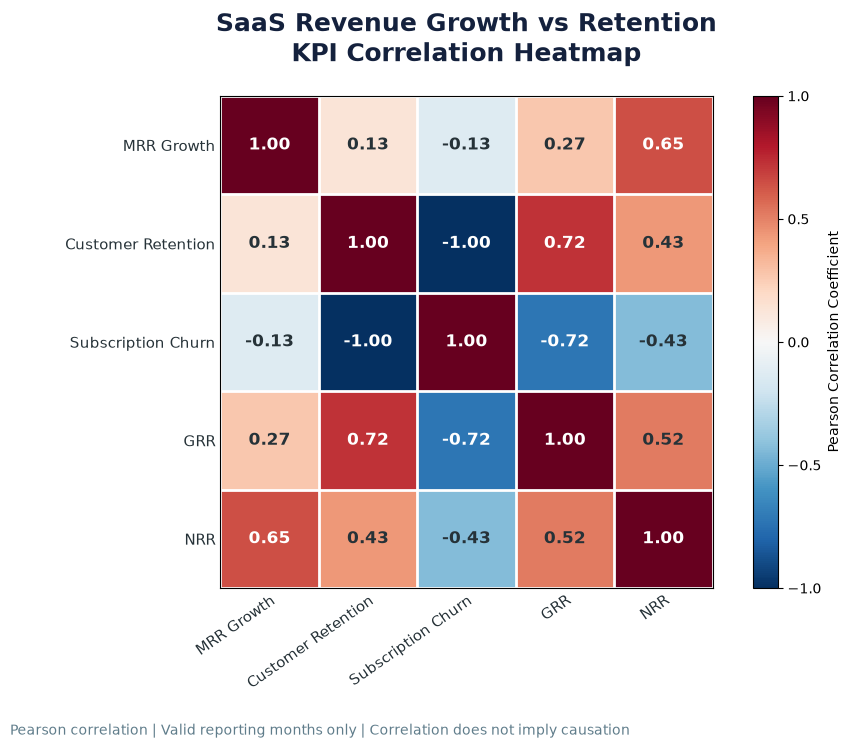

========== CORRELATION HEATMAP VALIDATION ==========
Chart Type: Correlation Heatmap
KPI Metrics: 5
Correlation Matrix Shape: (5, 5)
Saved File: revenue_growth_retention_correlation_heatmap.png
File Size (KB): 246.93
Heatmap Creation: PASS
File Export Validation: PASS


In [13]:

# ==========================================================
# STEP 6.3.2 - PART D
# REVENUE GROWTH VS RETENTION CORRELATION HEATMAP
# ==========================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# ----------------------------------------------------------
# 1. Set project and output paths
# ----------------------------------------------------------

project_root = Path.cwd().parent

figures_dir = project_root / "reports" / "figures"

figures_dir.mkdir(parents=True, exist_ok=True)

output_path = (
    figures_dir /
    "revenue_growth_retention_correlation_heatmap.png"
)

# ----------------------------------------------------------
# 2. Validate correlation matrix
# ----------------------------------------------------------

assert "correlation_matrix" in globals(), (
    "Run Step 6.3.2 Part C first."
)

assert correlation_matrix.shape == (5, 5), (
    "Expected a 5 x 5 correlation matrix."
)

assert correlation_matrix.index.equals(
    correlation_matrix.columns
), "Correlation matrix row/column labels mismatch."

# ----------------------------------------------------------
# 3. Prepare readable KPI labels
# ----------------------------------------------------------

label_mapping = {
    "MRR_Growth_Pct": "MRR Growth",
    "Customer_Retention_Rate_Pct": "Customer Retention",
    "Subscription_Churn_Rate_Pct": "Subscription Churn",
    "GRR_Pct": "GRR",
    "NRR_Pct": "NRR"
}

heatmap_df = correlation_matrix.rename(
    index=label_mapping,
    columns=label_mapping
)

# ----------------------------------------------------------
# 4. Create professional heatmap
# ----------------------------------------------------------

fig, ax = plt.subplots(figsize=(11, 8))

fig.patch.set_facecolor("#FFFFFF")
ax.set_facecolor("#FFFFFF")

heatmap_values = heatmap_df.to_numpy(dtype=float)

heatmap = ax.imshow(
    np.ma.masked_invalid(heatmap_values),
    cmap="RdBu_r",
    vmin=-1,
    vmax=1,
    interpolation="nearest"
)

# ----------------------------------------------------------
# 5. Add axis labels
# ----------------------------------------------------------

ax.set_xticks(np.arange(len(heatmap_df.columns)))
ax.set_yticks(np.arange(len(heatmap_df.index)))

ax.set_xticklabels(
    heatmap_df.columns,
    fontsize=11,
    fontweight="medium",
    color="#263238"
)

ax.set_yticklabels(
    heatmap_df.index,
    fontsize=11,
    fontweight="medium",
    color="#263238"
)

plt.setp(
    ax.get_xticklabels(),
    rotation=35,
    ha="right",
    rotation_mode="anchor"
)

# ----------------------------------------------------------
# 6. Add correlation values inside cells
# ----------------------------------------------------------

for i in range(len(heatmap_df.index)):

    for j in range(len(heatmap_df.columns)):

        value = heatmap_values[i, j]

        if np.isnan(value):
            display_value = "N/A"
            text_color = "#263238"

        else:
            display_value = f"{value:.2f}"

            text_color = (
                "white"
                if abs(value) >= 0.60
                else "#263238"
            )

        ax.text(
            j,
            i,
            display_value,
            ha="center",
            va="center",
            color=text_color,
            fontsize=12,
            fontweight="bold"
        )

# ----------------------------------------------------------
# 7. Add gridlines
# ----------------------------------------------------------

ax.set_xticks(
    np.arange(-0.5, len(heatmap_df.columns), 1),
    minor=True
)

ax.set_yticks(
    np.arange(-0.5, len(heatmap_df.index), 1),
    minor=True
)

ax.grid(
    which="minor",
    color="white",
    linewidth=2
)

ax.tick_params(
    which="minor",
    bottom=False,
    left=False
)

ax.tick_params(
    axis="both",
    which="major",
    length=0
)

# ----------------------------------------------------------
# 8. Add chart title and subtitle
# ----------------------------------------------------------

ax.set_title(
    "SaaS Revenue Growth vs Retention\n"
    "KPI Correlation Heatmap",
    fontsize=18,
    fontweight="bold",
    color="#14213D",
    pad=25
)

fig.text(
    0.5,
    0.035,
    "Pearson correlation | "
    "Valid reporting months only | "
    "Correlation does not imply causation",
    ha="center",
    fontsize=10,
    color="#607D8B"
)

# ----------------------------------------------------------
# 9. Add colorbar
# ----------------------------------------------------------

colorbar = fig.colorbar(
    heatmap,
    ax=ax,
    fraction=0.046,
    pad=0.04
)

colorbar.set_label(
    "Pearson Correlation Coefficient",
    fontsize=10
)

colorbar.set_ticks([-1, -0.5, 0, 0.5, 1])

# ----------------------------------------------------------
# 10. Save chart
# ----------------------------------------------------------

fig.tight_layout(
    rect=[0, 0.07, 1, 0.96]
)

fig.savefig(
    output_path,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

# ----------------------------------------------------------
# 11. Validate saved output
# ----------------------------------------------------------

assert output_path.exists(), (
    "Correlation heatmap file was not created."
)

assert output_path.stat().st_size > 0, (
    "Saved heatmap file is empty."
)

print("========== CORRELATION HEATMAP VALIDATION ==========")

print("Chart Type: Correlation Heatmap")
print("KPI Metrics:", len(heatmap_df.columns))
print("Correlation Matrix Shape:", heatmap_df.shape)

print("Saved File:", output_path.name)

print(
    "File Size (KB):",
    round(output_path.stat().st_size / 1024, 2)
)

print("Heatmap Creation: PASS")
print("File Export Validation: PASS")

print("====================================================")


In [14]:

# ==========================================================
# STEP 6.3.2 - PART E
# REVENUE GROWTH & RETENTION BUSINESS FINDINGS
# ==========================================================

import pandas as pd
import numpy as np
from pathlib import Path

# ----------------------------------------------------------
# 1. Set project and report paths
# ----------------------------------------------------------

project_root = Path.cwd().parent

reports_dir = project_root / "reports"
reports_dir.mkdir(parents=True, exist_ok=True)

report_path = (
    reports_dir /
    "Revenue_Growth_Retention_Business_Findings.md"
)

# ----------------------------------------------------------
# 2. Validate previous analysis outputs
# ----------------------------------------------------------

assert not analysis_df.empty, (
    "Run Step 6.3.2 Part B first."
)

assert len(insights_summary) == 14, (
    "Expected 14 business summary metrics."
)

assert len(correlation_summary) == 4, (
    "Expected 4 correlation comparisons."
)

assert correlation_matrix.shape == (5, 5), (
    "Expected a 5 x 5 correlation matrix."
)

# ----------------------------------------------------------
# 3. Prepare business findings
# ----------------------------------------------------------

avg_growth = analysis_df["MRR_Growth_Pct"].mean()

avg_customer_retention = (
    analysis_df["Customer_Retention_Rate_Pct"].mean()
)

avg_subscription_churn = (
    analysis_df["Subscription_Churn_Rate_Pct"].mean()
)

avg_grr = analysis_df["GRR_Pct"].mean()
avg_nrr = analysis_df["NRR_Pct"].mean()

positive_months = int(
    (analysis_df["MRR_Growth_Pct"] > 0).sum()
)

negative_months = int(
    (analysis_df["MRR_Growth_Pct"] < 0).sum()
)

expansion_months = int(
    (analysis_df["NRR_Pct"] > 100).sum()
)

revenue_loss_months = int(
    (analysis_df["NRR_Pct"] < 100).sum()
)

# ----------------------------------------------------------
# 4. Prepare correlation findings
# ----------------------------------------------------------

correlation_lines = []

for _, row in correlation_summary.iterrows():

    metric = row["Comparison_Metric"]
    value = row["Pearson_Correlation"]
    direction = row["Direction"]
    strength = row["Relationship_Strength"]

    if pd.isna(value):

        finding = (
            f"- **{metric}:** Correlation undefined "
            f"because sufficient metric variation "
            f"was not available."
        )

    else:

        finding = (
            f"- **{metric}:** Pearson r = {value:.4f}; "
            f"{direction.lower()} association; "
            f"{strength.lower()} linear relationship."
        )

    correlation_lines.append(finding)

correlation_findings = "\n".join(correlation_lines)

# ----------------------------------------------------------
# 5. Identify strongest observed correlation
# ----------------------------------------------------------

valid_corr = correlation_summary.dropna(
    subset=["Pearson_Correlation"]
).copy()

if not valid_corr.empty:

    valid_corr["Absolute_Correlation"] = (
        valid_corr["Pearson_Correlation"].abs()
    )

    strongest = valid_corr.sort_values(
        "Absolute_Correlation",
        ascending=False
    ).iloc[0]

    strongest_finding = (
        f"The strongest observed linear association "
        f"with monthly MRR growth was "
        f"**{strongest['Comparison_Metric']}**, "
        f"with Pearson r = "
        f"**{strongest['Pearson_Correlation']:.4f}**."
    )

else:

    strongest_finding = (
        "No valid Pearson correlations were available."
    )

# ----------------------------------------------------------
# 6. Generate professional Markdown report
# ----------------------------------------------------------

report_content = f"""# SaaS Revenue Growth & Retention Business Findings

## 1. Analysis Overview

This analysis evaluates the relationship between monthly
recurring revenue growth and customer/subscription retention
performance.

- Reporting months analyzed: **{len(analysis_df)}**
- Dataset: SaaS Monthly KPI Summary
- Analysis: Descriptive KPI analysis and Pearson correlation
- First reporting month excluded from comparative analysis
  because its opening-base retention metrics are undefined.

## 2. Revenue Growth Performance

- Average monthly MRR growth: **{avg_growth:.2f}%**
- Months with positive MRR growth: **{positive_months}**
- Months with negative MRR growth: **{negative_months}**

These results describe the direction and average rate of
monthly recurring revenue changes during valid reporting periods.

## 3. Customer & Subscription Retention

- Average monthly customer retention: **{avg_customer_retention:.2f}%**
- Average monthly subscription churn: **{avg_subscription_churn:.2f}%**

Customer retention measures the proportion of opening paying
customers retained during each reporting period.

Subscription churn measures the proportion of opening paid
subscriptions that churned during each reporting period.

## 4. Revenue Retention Performance

- Average monthly GRR: **{avg_grr:.2f}%**
- Average monthly NRR: **{avg_nrr:.2f}%**
- Months with net revenue expansion (NRR > 100%): **{expansion_months}**
- Months with net revenue loss (NRR < 100%): **{revenue_loss_months}**

GRR measures recurring revenue retention without expansion.

NRR incorporates expansion, contraction, and churn
within the existing revenue base.

## 5. Revenue Growth vs Retention Correlations

{correlation_findings}

### Strongest Observed Association

{strongest_finding}

Correlation indicates the direction and strength of
a linear association. It does not establish causation.

Some revenue metrics share underlying components,
so their correlation may partly reflect mathematical overlap.

## 6. Business Implications

1. Monitor MRR growth alongside customer and subscription
   retention rather than evaluating revenue growth alone.
2. Track churn to identify months with greater subscription
   losses relative to the opening subscription base.
3. Compare GRR and NRR to understand the contribution of
   expansion revenue to existing-customer revenue retention.
4. Investigate months with negative MRR growth or NRR below
   100% before recommending corrective business actions.
5. Treat correlation findings as exploratory evidence,
   not proof of business drivers.

## 7. Visualization

![Revenue Growth vs Retention Correlation Heatmap](figures/revenue_growth_retention_correlation_heatmap.png)

## 8. Methodology & Limitations

- All percentage averages are arithmetic averages of
  monthly KPI percentages, not weighted overall rates.
- The first reporting month was excluded from comparative
  analysis because its retention denominators were zero.
- Pearson correlation measures linear association only.
- Correlation does not imply causation.
- The dataset is synthetic, so findings should not be
  generalized to real SaaS companies without validation.
- Business recommendations require additional investigation
  of customer segments, revenue movements, and churn causes.

## 9. Analysis Status

- Revenue Growth KPI Analysis: Completed
- Retention KPI Analysis: Completed
- Pearson Correlation Analysis: Completed
- Correlation Heatmap: Completed
- Business Findings Report: Completed
"""

# ----------------------------------------------------------
# 7. Export Markdown report
# ----------------------------------------------------------

report_path.write_text(
    report_content,
    encoding="utf-8"
)

# ----------------------------------------------------------
# 8. Validate report
# ----------------------------------------------------------

assert report_path.exists(), (
    "Business findings report was not created."
)

assert report_path.stat().st_size > 0, (
    "Business findings report is empty."
)

required_sections = [
    "Analysis Overview",
    "Revenue Growth Performance",
    "Customer & Subscription Retention",
    "Revenue Retention Performance",
    "Revenue Growth vs Retention Correlations",
    "Business Implications",
    "Visualization",
    "Methodology & Limitations"
]

for section in required_sections:

    assert section in report_content, (
        f"Missing report section: {section}"
    )

heatmap_path = (
    reports_dir /
    "figures" /
    "revenue_growth_retention_correlation_heatmap.png"
)

assert heatmap_path.exists(), (
    "Correlation heatmap image not found."
)

# ----------------------------------------------------------
# 9. Display final output
# ----------------------------------------------------------

print("========== BUSINESS FINDINGS REPORT ==========")

print("Report:", report_path.name)
print("Reporting Months:", len(analysis_df))
print("Summary Metrics:", len(insights_summary))
print("Correlation Comparisons:", len(correlation_summary))
print("Report Sections Validated:", len(required_sections))

print(
    "Report Size (KB):",
    round(report_path.stat().st_size / 1024, 2)
)

print("Markdown Report Export: PASS")
print("Heatmap Reference Validation: PASS")
print("Business Findings Report Validation: PASS")

print("==============================================")


========== BUSINESS FINDINGS REPORT ==========
Report: Revenue_Growth_Retention_Business_Findings.md
Reporting Months: 29
Summary Metrics: 14
Correlation Comparisons: 4
Report Sections Validated: 8
Report Size (KB): 3.8
Markdown Report Export: PASS
Heatmap Reference Validation: PASS
Business Findings Report Validation: PASS


In [15]:

# ==========================================================
# STEP 6.3.2 - PART F
# FINAL VALIDATION & CONSISTENCY CHECKS
# ==========================================================

import pandas as pd
import numpy as np
from pathlib import Path

# ----------------------------------------------------------
# 1. Validate project paths
# ----------------------------------------------------------

project_root = Path.cwd().parent

report_path = (
    project_root
    / "reports"
    / "Revenue_Growth_Retention_Business_Findings.md"
)

heatmap_path = (
    project_root
    / "reports"
    / "figures"
    / "revenue_growth_retention_correlation_heatmap.png"
)

# ----------------------------------------------------------
# 2. Validate required DataFrames
# ----------------------------------------------------------

required_dataframes = {
    "business_performance": business_performance,
    "growth_retention_df": growth_retention_df,
    "valid_growth_retention": valid_growth_retention,
    "analysis_df": analysis_df,
    "insights_summary": insights_summary,
    "correlation_summary": correlation_summary,
    "correlation_matrix": correlation_matrix
}

for name, df in required_dataframes.items():

    assert isinstance(df, pd.DataFrame), (
        f"{name} is not a DataFrame."
    )

    assert not df.empty, (
        f"{name} is empty."
    )

print("DataFrame Availability: PASS")

# ----------------------------------------------------------
# 3. Validate reporting period consistency
# ----------------------------------------------------------

assert len(growth_retention_df) == len(
    business_performance
), "Reporting period count mismatch."

assert growth_retention_df["Month"].is_unique, (
    "Duplicate reporting months detected."
)

assert growth_retention_df["Month"].notna().all(), (
    "Missing reporting dates detected."
)

assert len(analysis_df) == len(
    valid_growth_retention
), "Analysis dataset count mismatch."

assert analysis_df["Month"].equals(
    valid_growth_retention["Month"]
), "Analysis reporting months do not match."

print("Reporting Period Consistency: PASS")

# ----------------------------------------------------------
# 4. Validate January missing retention values
# ----------------------------------------------------------

retention_metrics = [
    "Subscription_Churn_Rate_Pct",
    "Subscription_Retention_Rate_Pct",
    "Customer_Retention_Rate_Pct",
    "GRR_Pct",
    "NRR_Pct"
]

first_month = growth_retention_df.sort_values(
    "Month"
).iloc[0]

assert first_month["Month"] == pd.Timestamp(
    "2024-01-01"
), "Unexpected first reporting month."

assert first_month[retention_metrics].isna().all(), (
    "First-month retention values differ from diagnosis."
)

assert growth_retention_df[
    retention_metrics
].iloc[1:].notna().all().all(), (
    "Missing retention values after first month."
)

print("First-Month Missing Value Handling: PASS")

# ----------------------------------------------------------
# 5. Validate summary metrics
# ----------------------------------------------------------

assert len(insights_summary) == 14, (
    "Expected 14 business metrics."
)

assert insights_summary[
    "Business_Metric"
].is_unique, "Duplicate summary metrics found."

metric_lookup = insights_summary.set_index(
    "Business_Metric"
)["Value"]

checks = {
    "Average MRR Growth (%)":
        analysis_df["MRR_Growth_Pct"].mean(),

    "Average Customer Retention (%)":
        analysis_df["Customer_Retention_Rate_Pct"].mean(),

    "Average Subscription Churn (%)":
        analysis_df["Subscription_Churn_Rate_Pct"].mean(),

    "Average GRR (%)":
        analysis_df["GRR_Pct"].mean(),

    "Average NRR (%)":
        analysis_df["NRR_Pct"].mean()
}

for metric_name, expected_value in checks.items():

    actual_value = float(metric_lookup.loc[metric_name])

    assert np.isclose(
        actual_value,
        round(expected_value, 2),
        atol=0.01
    ), f"Summary mismatch: {metric_name}"

print("Business Summary KPI Consistency: PASS")

# ----------------------------------------------------------
# 6. Validate correlation outputs
# ----------------------------------------------------------

assert correlation_summary.shape[0] == 4, (
    "Expected four correlation comparisons."
)

assert correlation_matrix.shape == (5, 5), (
    "Expected a 5 x 5 correlation matrix."
)

for _, row in correlation_summary.iterrows():

    metric = row["Comparison_Metric"]

    expected_r = correlation_matrix.loc[
        "MRR_Growth_Pct",
        metric
    ]

    actual_r = row["Pearson_Correlation"]

    if pd.isna(expected_r):
        assert pd.isna(actual_r), (
            f"Correlation mismatch: {metric}"
        )

    else:
        assert np.isclose(
            actual_r,
            expected_r,
            atol=0.0001
        ), f"Correlation mismatch: {metric}"

print("Correlation Result Consistency: PASS")

# ----------------------------------------------------------
# 7. Validate generated deliverables
# ----------------------------------------------------------

assert report_path.is_file(), (
    "Business findings Markdown report missing."
)

assert heatmap_path.is_file(), (
    "Correlation heatmap PNG missing."
)

assert report_path.stat().st_size > 0, (
    "Markdown report is empty."
)

assert heatmap_path.stat().st_size > 0, (
    "Heatmap PNG is empty."
)

report_text = report_path.read_text(
    encoding="utf-8"
)

assert (
    "figures/revenue_growth_retention_correlation_heatmap.png"
    in report_text
), "Heatmap reference missing from report."

print("Report & Heatmap File Validation: PASS")

# ----------------------------------------------------------
# 8. Display final validation summary
# ----------------------------------------------------------

validation_summary = pd.DataFrame(
    [
        ["DataFrame Availability", "PASS"],
        ["Reporting Period Consistency", "PASS"],
        ["First-Month Missing Value Handling", "PASS"],
        ["Business Summary KPI Consistency", "PASS"],
        ["Correlation Result Consistency", "PASS"],
        ["Report & Heatmap File Validation", "PASS"]
    ],
    columns=["Validation_Check", "Status"]
)

print("\n========== FINAL VALIDATION SUMMARY ==========")

display(validation_summary)

print("Total Validation Checks:", len(validation_summary))

print(
    "Passed Checks:",
    (validation_summary["Status"] == "PASS").sum()
)

print("Overall Step 6.3.2 Validation: PASS")

print("==============================================")


DataFrame Availability: PASS
Reporting Period Consistency: PASS
First-Month Missing Value Handling: PASS
Business Summary KPI Consistency: PASS
Correlation Result Consistency: PASS
Report & Heatmap File Validation: PASS

========== FINAL VALIDATION SUMMARY ==========


,Validation_Check,Status
0,DataFrame Availability,PASS
1,Reporting Period Consistency,PASS
2,First-Month Missing Value Handling,PASS
3,Business Summary KPI Consistency,PASS
4,Correlation Result Consistency,PASS
5,Report & Heatmap File Validation,PASS


Total Validation Checks: 6
Passed Checks: 6
Overall Step 6.3.2 Validation: PASS


In [16]:

# ==========================================================
# STEP 6.3.3 - PART A
# MONTHLY SaaS BUSINESS PERFORMANCE SCORECARD
# ==========================================================

import pandas as pd
import numpy as np

# ----------------------------------------------------------
# 1. Validate source DataFrame
# ----------------------------------------------------------

required_columns = [
    "Month",
    "Year_Month",
    "Total_MRR_USD",
    "MRR_Growth_Pct",
    "Customer_Retention_Rate_Pct",
    "Subscription_Churn_Rate_Pct",
    "GRR_Pct",
    "NRR_Pct"
]

missing_columns = [
    col for col in required_columns
    if col not in business_performance.columns
]

assert not missing_columns, (
    f"Missing required columns: {missing_columns}"
)

# ----------------------------------------------------------
# 2. Create monthly performance scorecard
# ----------------------------------------------------------

performance_scorecard = (
    business_performance[required_columns]
    .copy()
    .sort_values("Month")
    .reset_index(drop=True)
)

performance_scorecard["Month"] = pd.to_datetime(
    performance_scorecard["Month"],
    errors="coerce"
)

numeric_columns = [
    col for col in required_columns
    if col not in ["Month", "Year_Month"]
]

performance_scorecard[numeric_columns] = (
    performance_scorecard[numeric_columns]
    .apply(pd.to_numeric, errors="coerce")
)

# ----------------------------------------------------------
# 3. Classify monthly MRR growth
# ----------------------------------------------------------

performance_scorecard["Growth_Status"] = np.select(
    [
        performance_scorecard["MRR_Growth_Pct"] > 0,
        performance_scorecard["MRR_Growth_Pct"] < 0,
        performance_scorecard["MRR_Growth_Pct"] == 0
    ],
    [
        "Growing",
        "Declining",
        "Stable"
    ],
    default="Not Available"
)

# ----------------------------------------------------------
# 4. Classify net revenue retention
# ----------------------------------------------------------

performance_scorecard["Revenue_Retention_Status"] = np.select(
    [
        performance_scorecard["NRR_Pct"] > 100,
        performance_scorecard["NRR_Pct"] < 100,
        performance_scorecard["NRR_Pct"] == 100
    ],
    [
        "Net Expansion",
        "Net Revenue Loss",
        "Fully Retained"
    ],
    default="Not Available"
)

# ----------------------------------------------------------
# 5. Classify GRR performance
# ----------------------------------------------------------

# These are descriptive bands for this project,
# not universal SaaS industry benchmarks.

performance_scorecard["GRR_Status"] = np.select(
    [
        performance_scorecard["GRR_Pct"] >= 95,
        performance_scorecard["GRR_Pct"] >= 90,
        performance_scorecard["GRR_Pct"] < 90
    ],
    [
        "High Retention",
        "Moderate Retention",
        "Lower Retention"
    ],
    default="Not Available"
)

# ----------------------------------------------------------
# 6. Identify months with complete KPI data
# ----------------------------------------------------------

scorecard_metrics = [
    "MRR_Growth_Pct",
    "Customer_Retention_Rate_Pct",
    "Subscription_Churn_Rate_Pct",
    "GRR_Pct",
    "NRR_Pct"
]

performance_scorecard["Complete_KPI_Data"] = (
    performance_scorecard[scorecard_metrics]
    .notna()
    .all(axis=1)
)

# ----------------------------------------------------------
# 7. Validate scorecard
# ----------------------------------------------------------

assert not performance_scorecard.empty, (
    "Performance scorecard is empty."
)

assert len(performance_scorecard) == len(
    business_performance
), "Reporting month count mismatch."

assert performance_scorecard["Month"].notna().all(), (
    "Invalid reporting dates detected."
)

assert performance_scorecard["Month"].is_unique, (
    "Duplicate reporting months detected."
)

assert performance_scorecard[
    "Total_MRR_USD"
].notna().all(), "Missing MRR values detected."

assert (
    performance_scorecard["Total_MRR_USD"] >= 0
).all(), "Negative MRR detected."

assert np.isfinite(
    performance_scorecard[numeric_columns]
    .to_numpy(dtype=float)[
        ~np.isnan(
            performance_scorecard[numeric_columns]
            .to_numpy(dtype=float)
        )
    ]
).all(), "Infinite numeric KPI values detected."

# ----------------------------------------------------------
# 8. Display scorecard preparation summary
# ----------------------------------------------------------

print("========== SaaS PERFORMANCE SCORECARD ==========")

print(
    "Total Reporting Months:",
    len(performance_scorecard)
)

print(
    "Months With Complete KPI Data:",
    performance_scorecard["Complete_KPI_Data"].sum()
)

print(
    "Months With Incomplete KPI Data:",
    (~performance_scorecard["Complete_KPI_Data"]).sum()
)

print(
    "Growing Months:",
    (performance_scorecard["Growth_Status"] == "Growing").sum()
)

print(
    "Declining Months:",
    (performance_scorecard["Growth_Status"] == "Declining").sum()
)

print(
    "Net Expansion Months:",
    (
        performance_scorecard["Revenue_Retention_Status"]
        == "Net Expansion"
    ).sum()
)

print("Scorecard Data Preparation: PASS")
print("Reporting Month Validation: PASS")
print("Overall Scorecard Validation: PASS")

print("================================================")

# ----------------------------------------------------------
# 9. Preview final scorecard
# ----------------------------------------------------------

display(
    performance_scorecard[
        [
            "Year_Month",
            "Total_MRR_USD",
            "MRR_Growth_Pct",
            "Growth_Status",
            "Customer_Retention_Rate_Pct",
            "Subscription_Churn_Rate_Pct",
            "GRR_Pct",
            "GRR_Status",
            "NRR_Pct",
            "Revenue_Retention_Status",
            "Complete_KPI_Data"
        ]
    ].head(10)
)


========== SaaS PERFORMANCE SCORECARD ==========
Total Reporting Months: 30
Months With Complete KPI Data: 29
Months With Incomplete KPI Data: 1
Growing Months: 29
Declining Months: 0
Net Expansion Months: 22
Scorecard Data Preparation: PASS
Reporting Month Validation: PASS
Overall Scorecard Validation: PASS


,Year_Month,Total_MRR_USD,MRR_Growth_Pct,Growth_Status,Customer_Retention_Rate_Pct,Subscription_Churn_Rate_Pct,GRR_Pct,GRR_Status,NRR_Pct,Revenue_Retention_Status,Complete_KPI_Data
0,2024-01,145853.24,NaN,Not Available,NaN,NaN,NaN,Not Available,NaN,Not Available,False
1,2024-02,151051.80,3.56,Growing,97.20,2.80,98.01,High Retention,98.88,Net Revenue Loss,True
2,2024-03,155769.21,3.12,Growing,97.01,2.99,97.96,High Retention,101.77,Net Expansion,True
3,2024-04,163530.40,4.98,Growing,97.41,2.59,98.06,High Retention,101.15,Net Expansion,True
4,2024-05,171524.29,4.89,Growing,97.42,2.58,98.45,High Retention,102.55,Net Expansion,True
5,2024-06,177113.30,3.26,Growing,98.10,1.90,99.05,High Retention,100.76,Net Expansion,True
6,2024-07,185335.76,4.64,Growing,98.12,1.88,99.19,High Retention,102.91,Net Expansion,True
7,2024-08,192664.71,3.95,Growing,98.35,1.65,99.32,High Retention,102.19,Net Expansion,True
8,2024-09,201173.32,4.42,Growing,97.17,2.83,98.42,High Retention,100.16,Net Expansion,True
9,2024-10,206885.58,2.84,Growing,97.25,2.75,97.49,High Retention,99.16,Net Revenue Loss,True


In [17]:

# ==========================================================
# STEP 6.3.3 - PART B
# MONTHLY SaaS BUSINESS PERFORMANCE SCORECARD ANALYSIS
# ==========================================================

import pandas as pd
import numpy as np

# ----------------------------------------------------------
# 1. Validate prepared scorecard
# ----------------------------------------------------------

assert "performance_scorecard" in globals(), (
    "Run Step 6.3.3 Part A first."
)

assert not performance_scorecard.empty, (
    "Performance scorecard is empty."
)

scorecard_analysis = performance_scorecard.copy()

valid_scorecard = (
    scorecard_analysis[
        scorecard_analysis["Complete_KPI_Data"]
    ]
    .copy()
    .reset_index(drop=True)
)

assert not valid_scorecard.empty, (
    "No months with complete KPI data."
)

# ----------------------------------------------------------
# 2. Analyze MRR growth categories
# ----------------------------------------------------------

growth_counts = (
    scorecard_analysis["Growth_Status"]
    .value_counts()
    .reindex(
        [
            "Growing",
            "Declining",
            "Stable",
            "Not Available"
        ],
        fill_value=0
    )
)

growth_summary = (
    growth_counts
    .rename_axis("Growth_Status")
    .reset_index(name="Months")
)

growth_summary["Percentage"] = (
    growth_summary["Months"]
    / len(scorecard_analysis)
    * 100
).round(2)

# ----------------------------------------------------------
# 3. Analyze net revenue retention categories
# ----------------------------------------------------------

retention_counts = (
    scorecard_analysis["Revenue_Retention_Status"]
    .value_counts()
    .reindex(
        [
            "Net Expansion",
            "Net Revenue Loss",
            "Fully Retained",
            "Not Available"
        ],
        fill_value=0
    )
)

revenue_retention_summary = (
    retention_counts
    .rename_axis("Revenue_Retention_Status")
    .reset_index(name="Months")
)

revenue_retention_summary["Percentage"] = (
    revenue_retention_summary["Months"]
    / len(scorecard_analysis)
    * 100
).round(2)

# ----------------------------------------------------------
# 4. Analyze GRR performance categories
# ----------------------------------------------------------

grr_counts = (
    scorecard_analysis["GRR_Status"]
    .value_counts()
    .reindex(
        [
            "High Retention",
            "Moderate Retention",
            "Lower Retention",
            "Not Available"
        ],
        fill_value=0
    )
)

grr_summary = (
    grr_counts
    .rename_axis("GRR_Status")
    .reset_index(name="Months")
)

grr_summary["Percentage"] = (
    grr_summary["Months"]
    / len(scorecard_analysis)
    * 100
).round(2)

# ----------------------------------------------------------
# 5. Identify best and weakest MRR growth months
# ----------------------------------------------------------

highest_growth_month = valid_scorecard.loc[
    valid_scorecard["MRR_Growth_Pct"].idxmax()
]

lowest_growth_month = valid_scorecard.loc[
    valid_scorecard["MRR_Growth_Pct"].idxmin()
]

# ----------------------------------------------------------
# 6. Identify strongest and weakest NRR months
# ----------------------------------------------------------

highest_nrr_month = valid_scorecard.loc[
    valid_scorecard["NRR_Pct"].idxmax()
]

lowest_nrr_month = valid_scorecard.loc[
    valid_scorecard["NRR_Pct"].idxmin()
]

# ----------------------------------------------------------
# 7. Calculate overall descriptive metrics
# ----------------------------------------------------------

average_mrr_growth = (
    valid_scorecard["MRR_Growth_Pct"].mean()
)

average_customer_retention = (
    valid_scorecard[
        "Customer_Retention_Rate_Pct"
    ].mean()
)

average_subscription_churn = (
    valid_scorecard[
        "Subscription_Churn_Rate_Pct"
    ].mean()
)

average_grr = valid_scorecard["GRR_Pct"].mean()

average_nrr = valid_scorecard["NRR_Pct"].mean()

# ----------------------------------------------------------
# 8. Display analysis results
# ----------------------------------------------------------

print("========== SaaS SCORECARD PERFORMANCE ANALYSIS ==========")

print("\n--- MRR GROWTH STATUS ---")
display(growth_summary)

print("\n--- NET REVENUE RETENTION STATUS ---")
display(revenue_retention_summary)

print("\n--- GRR PERFORMANCE STATUS ---")
display(grr_summary)

print("\n--- BEST AND WEAKEST MONTHS ---")

print(
    "Highest MRR Growth:",
    highest_growth_month["Year_Month"],
    f"({highest_growth_month['MRR_Growth_Pct']:.2f}%)"
)

print(
    "Lowest MRR Growth:",
    lowest_growth_month["Year_Month"],
    f"({lowest_growth_month['MRR_Growth_Pct']:.2f}%)"
)

print(
    "Highest NRR:",
    highest_nrr_month["Year_Month"],
    f"({highest_nrr_month['NRR_Pct']:.2f}%)"
)

print(
    "Lowest NRR:",
    lowest_nrr_month["Year_Month"],
    f"({lowest_nrr_month['NRR_Pct']:.2f}%)"
)

print("\n--- AVERAGE MONTHLY KPI PERFORMANCE ---")

print(f"Average MRR Growth: {average_mrr_growth:.2f}%")
print(f"Average Customer Retention: {average_customer_retention:.2f}%")
print(f"Average Subscription Churn: {average_subscription_churn:.2f}%")
print(f"Average GRR: {average_grr:.2f}%")
print(f"Average NRR: {average_nrr:.2f}%")

# ----------------------------------------------------------
# 9. Validate scorecard summaries
# ----------------------------------------------------------

assert growth_summary["Months"].sum() == len(
    scorecard_analysis
), "Growth status count mismatch."

assert revenue_retention_summary["Months"].sum() == len(
    scorecard_analysis
), "Revenue retention status count mismatch."

assert grr_summary["Months"].sum() == len(
    scorecard_analysis
), "GRR status count mismatch."

assert len(valid_scorecard) == int(
    scorecard_analysis["Complete_KPI_Data"].sum()
), "Valid reporting month count mismatch."

assert np.isfinite(
    [
        average_mrr_growth,
        average_customer_retention,
        average_subscription_churn,
        average_grr,
        average_nrr
    ]
).all(), "Invalid average KPI values detected."

print("\n--- VALIDATION RESULTS ---")

print("MRR Growth Status Validation: PASS")
print("Revenue Retention Status Validation: PASS")
print("GRR Status Validation: PASS")
print("Valid Reporting Month Validation: PASS")
print("Average KPI Validation: PASS")

print("\nOverall Scorecard Analysis: PASS")

print("=======================================================")


========== SaaS SCORECARD PERFORMANCE ANALYSIS ==========

--- MRR GROWTH STATUS ---


,Growth_Status,Months,Percentage
0,Growing,29,96.67
1,Declining,0,0.00
2,Stable,0,0.00
3,Not Available,1,3.33



--- NET REVENUE RETENTION STATUS ---


,Revenue_Retention_Status,Months,Percentage
0,Net Expansion,22,73.33
1,Net Revenue Loss,7,23.33
2,Fully Retained,0,0.00
3,Not Available,1,3.33



--- GRR PERFORMANCE STATUS ---


,GRR_Status,Months,Percentage
0,High Retention,29,96.67
1,Moderate Retention,0,0.00
2,Lower Retention,0,0.00
3,Not Available,1,3.33



--- BEST AND WEAKEST MONTHS ---
Highest MRR Growth: 2024-11 (8.38%)
Lowest MRR Growth: 2026-01 (1.08%)
Highest NRR: 2024-11 (103.24%)
Lowest NRR: 2024-02 (98.88%)

--- AVERAGE MONTHLY KPI PERFORMANCE ---
Average MRR Growth: 4.09%
Average Customer Retention: 97.89%
Average Subscription Churn: 2.11%
Average GRR: 98.58%
Average NRR: 100.99%

--- VALIDATION RESULTS ---
MRR Growth Status Validation: PASS
Revenue Retention Status Validation: PASS
GRR Status Validation: PASS
Valid Reporting Month Validation: PASS
Average KPI Validation: PASS

Overall Scorecard Analysis: PASS


findfont: Failed to find font weight medium for DejaVu Sans, now using 400.


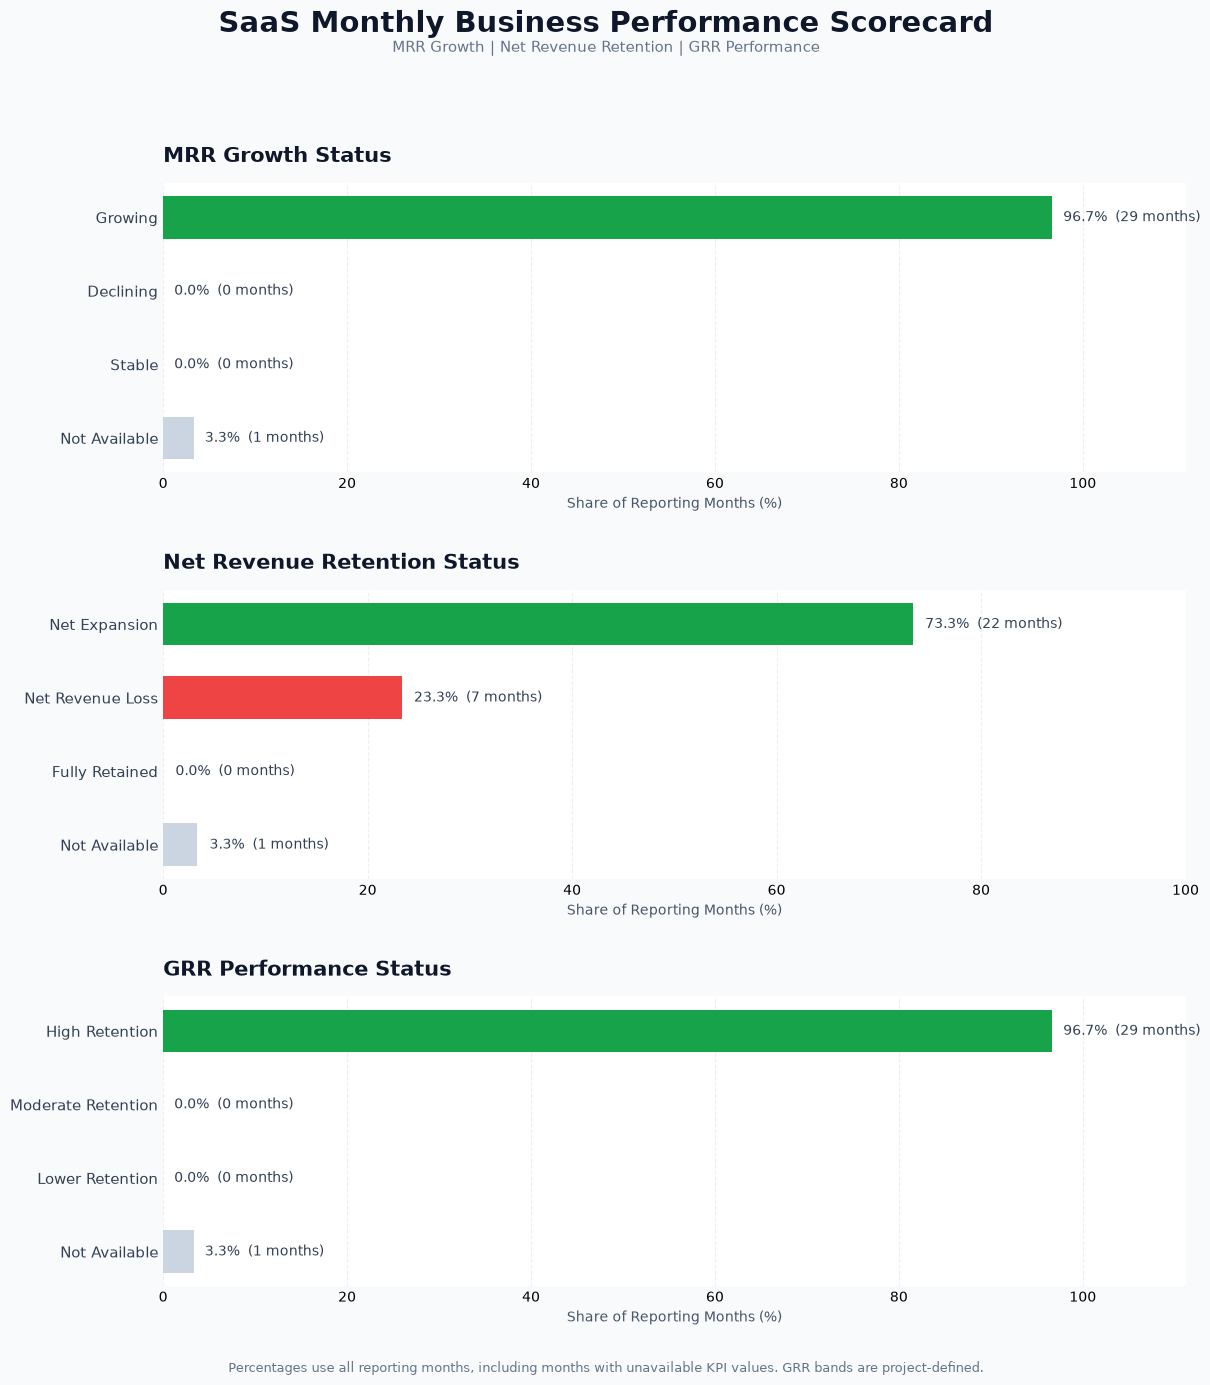

========== SCORECARD VISUALIZATION VALIDATION ==========
Chart Panels: 3
Reporting Months: 30
Output File: saas_monthly_business_performance_scorecard.png
File Size (KB): 419.65
Scorecard Visualization: PASS
PNG Export Validation: PASS


In [18]:

# ==========================================================
# STEP 6.3.3 - PART C
# MONTHLY SaaS PERFORMANCE SCORECARD VISUALIZATION
# ==========================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# ----------------------------------------------------------
# 1. Set project paths
# ----------------------------------------------------------

project_root = Path.cwd().parent

figures_dir = project_root / "reports" / "figures"
figures_dir.mkdir(parents=True, exist_ok=True)

output_path = (
    figures_dir /
    "saas_monthly_business_performance_scorecard.png"
)

# ----------------------------------------------------------
# 2. Validate Part B summaries
# ----------------------------------------------------------

summary_tables = {
    "MRR Growth": growth_summary,
    "Revenue Retention": revenue_retention_summary,
    "GRR Performance": grr_summary
}

for name, df in summary_tables.items():

    assert not df.empty, f"{name} summary is empty."

    assert {"Months", "Percentage"}.issubset(df.columns), (
        f"Missing columns in {name} summary."
    )

    assert df["Months"].sum() == len(scorecard_analysis), (
        f"Monthly totals mismatch in {name}."
    )

# ----------------------------------------------------------
# 3. Define chart configurations
# ----------------------------------------------------------

chart_configs = [
    {
        "data": growth_summary,
        "category": "Growth_Status",
        "title": "MRR Growth Status",
        "colors": {
            "Growing": "#16A34A",
            "Declining": "#EF4444",
            "Stable": "#64748B",
            "Not Available": "#CBD5E1"
        }
    },
    {
        "data": revenue_retention_summary,
        "category": "Revenue_Retention_Status",
        "title": "Net Revenue Retention Status",
        "colors": {
            "Net Expansion": "#16A34A",
            "Net Revenue Loss": "#EF4444",
            "Fully Retained": "#64748B",
            "Not Available": "#CBD5E1"
        }
    },
    {
        "data": grr_summary,
        "category": "GRR_Status",
        "title": "GRR Performance Status",
        "colors": {
            "High Retention": "#16A34A",
            "Moderate Retention": "#F59E0B",
            "Lower Retention": "#EF4444",
            "Not Available": "#CBD5E1"
        }
    }
]

# ----------------------------------------------------------
# 4. Create dashboard-style visualization
# ----------------------------------------------------------

fig, axes = plt.subplots(
    nrows=3,
    ncols=1,
    figsize=(13, 14)
)

fig.patch.set_facecolor("#F8FAFC")

for ax, config in zip(axes, chart_configs):

    df = config["data"].copy()

    category_col = config["category"]

    categories = df[category_col].tolist()
    counts = df["Months"].tolist()
    percentages = df["Percentage"].tolist()

    colors = [
        config["colors"].get(category, "#94A3B8")
        for category in categories
    ]

    y_positions = np.arange(len(categories))

    bars = ax.barh(
        y_positions,
        percentages,
        color=colors,
        height=0.58,
        edgecolor="none"
    )

    ax.set_yticks(y_positions)
    ax.set_yticklabels(
        categories,
        fontsize=11,
        color="#334155"
    )

    ax.invert_yaxis()

    ax.set_xlim(
        0,
        max(100, max(percentages) * 1.15)
    )

    ax.set_xlabel(
        "Share of Reporting Months (%)",
        fontsize=10,
        color="#475569"
    )

    ax.set_title(
        config["title"],
        fontsize=15,
        fontweight="bold",
        color="#0F172A",
        loc="left",
        pad=15
    )

    ax.set_facecolor("#FFFFFF")

    ax.grid(
        axis="x",
        linestyle="--",
        alpha=0.20
    )

    ax.set_axisbelow(True)

    for bar, count, percentage in zip(
        bars, counts, percentages
    ):

        ax.text(
            bar.get_width() + 1.2,
            bar.get_y() + bar.get_height() / 2,
            f"{percentage:.1f}%  ({count} months)",
            va="center",
            fontsize=10,
            fontweight="medium",
            color="#334155"
        )

    for spine in ax.spines.values():
        spine.set_visible(False)

    ax.tick_params(
        axis="both",
        length=0
    )

# ----------------------------------------------------------
# 5. Add dashboard heading
# ----------------------------------------------------------

fig.suptitle(
    "SaaS Monthly Business Performance Scorecard",
    fontsize=21,
    fontweight="bold",
    color="#0F172A",
    y=0.985
)

fig.text(
    0.5,
    0.955,
    "MRR Growth | Net Revenue Retention | GRR Performance",
    ha="center",
    fontsize=11,
    color="#64748B"
)

fig.text(
    0.5,
    0.012,
    "Percentages use all reporting months, including "
    "months with unavailable KPI values. "
    "GRR bands are project-defined.",
    ha="center",
    fontsize=9,
    color="#64748B"
)

# ----------------------------------------------------------
# 6. Adjust layout and save
# ----------------------------------------------------------

fig.tight_layout(
    rect=[0.03, 0.035, 0.97, 0.93],
    h_pad=3
)

fig.savefig(
    output_path,
    dpi=300,
    bbox_inches="tight",
    facecolor=fig.get_facecolor()
)

plt.show()

# ----------------------------------------------------------
# 7. Validate exported chart
# ----------------------------------------------------------

assert output_path.is_file(), (
    "Performance scorecard PNG was not created."
)

assert output_path.stat().st_size > 0, (
    "Saved performance scorecard PNG is empty."
)

print("========== SCORECARD VISUALIZATION VALIDATION ==========")

print("Chart Panels: 3")
print("Reporting Months:", len(scorecard_analysis))
print("Output File:", output_path.name)

print(
    "File Size (KB):",
    round(output_path.stat().st_size / 1024, 2)
)

print("Scorecard Visualization: PASS")
print("PNG Export Validation: PASS")

print("=======================================================")


In [26]:

# ==========================================================
# STEP 6.3.3 - PART D - STEP 1
# GENERATE SaaS BUSINESS PERFORMANCE FINDINGS REPORT
# ==========================================================

import pandas as pd
from pathlib import Path

# ----------------------------------------------------------
# 1. Define project paths
# ----------------------------------------------------------

project_root = Path.cwd().parent

reports_dir = project_root / "reports"
reports_dir.mkdir(parents=True, exist_ok=True)

report_path = (
    reports_dir /
    "SaaS_Business_Performance_Scorecard_Findings.md"
)

chart_path = (
    reports_dir /
    "figures" /
    "saas_monthly_business_performance_scorecard.png"
)

# ----------------------------------------------------------
# 2. Validate Part B and Part C results
# ----------------------------------------------------------

assert not performance_scorecard.empty, (
    "Performance scorecard is empty."
)

assert not valid_scorecard.empty, (
    "Valid scorecard is empty."
)

assert chart_path.is_file(), (
    "Part C visualization PNG not found."
)

# ----------------------------------------------------------
# 3. Calculate business performance metrics
# ----------------------------------------------------------

total_months = len(performance_scorecard)
valid_months = len(valid_scorecard)

def count_status(column, status):
    return int(
        (performance_scorecard[column] == status).sum()
    )

growing = count_status("Growth_Status", "Growing")
declining = count_status("Growth_Status", "Declining")
stable = count_status("Growth_Status", "Stable")
growth_na = count_status("Growth_Status", "Not Available")

expansion = count_status(
    "Revenue_Retention_Status", "Net Expansion"
)

revenue_loss = count_status(
    "Revenue_Retention_Status", "Net Revenue Loss"
)

fully_retained = count_status(
    "Revenue_Retention_Status", "Fully Retained"
)

nrr_na = count_status(
    "Revenue_Retention_Status", "Not Available"
)

high_grr = count_status("GRR_Status", "High Retention")

moderate_grr = count_status(
    "GRR_Status", "Moderate Retention"
)

lower_grr = count_status("GRR_Status", "Lower Retention")

grr_na = count_status("GRR_Status", "Not Available")

# ----------------------------------------------------------
# 4. Calculate average monthly KPIs
# ----------------------------------------------------------

avg_growth = valid_scorecard["MRR_Growth_Pct"].mean()

avg_customer_retention = valid_scorecard[
    "Customer_Retention_Rate_Pct"
].mean()

avg_subscription_churn = valid_scorecard[
    "Subscription_Churn_Rate_Pct"
].mean()

avg_grr = valid_scorecard["GRR_Pct"].mean()

avg_nrr = valid_scorecard["NRR_Pct"].mean()

# ----------------------------------------------------------
# 5. Identify strongest and weakest months
# ----------------------------------------------------------

best_growth = valid_scorecard.loc[
    valid_scorecard["MRR_Growth_Pct"].idxmax()
]

worst_growth = valid_scorecard.loc[
    valid_scorecard["MRR_Growth_Pct"].idxmin()
]

best_nrr = valid_scorecard.loc[
    valid_scorecard["NRR_Pct"].idxmax()
]

worst_nrr = valid_scorecard.loc[
    valid_scorecard["NRR_Pct"].idxmin()
]

# ----------------------------------------------------------
# 6. Validate category totals
# ----------------------------------------------------------

assert (
    growing + declining + stable + growth_na
    == total_months
), "MRR Growth category count mismatch."

assert (
    expansion + revenue_loss + fully_retained + nrr_na
    == total_months
), "NRR category count mismatch."

assert (
    high_grr + moderate_grr + lower_grr + grr_na
    == total_months
), "GRR category count mismatch."

# ----------------------------------------------------------
# 7. Generate Markdown business findings
# ----------------------------------------------------------

report_content = f"""# SaaS Business Performance Scorecard Findings

## 1. Executive Summary

This report analyzes SaaS monthly business performance
using MRR growth, customer retention, subscription churn,
Gross Revenue Retention (GRR), and Net Revenue Retention (NRR).

- Total reporting months: **{total_months}**
- Months with complete KPI data: **{valid_months}**
- Average monthly MRR growth: **{avg_growth:.2f}%**
- Average monthly customer retention: **{avg_customer_retention:.2f}%**
- Average monthly subscription churn: **{avg_subscription_churn:.2f}%**
- Average monthly GRR: **{avg_grr:.2f}%**
- Average monthly NRR: **{avg_nrr:.2f}%**

## 2. MRR Growth Performance

- Growing months: **{growing}**
- Declining months: **{declining}**
- Stable months: **{stable}**
- Growth data unavailable: **{growth_na}**

Highest MRR growth:
**{best_growth['Year_Month']}**
({best_growth['MRR_Growth_Pct']:.2f}%)

Lowest MRR growth:
**{worst_growth['Year_Month']}**
({worst_growth['MRR_Growth_Pct']:.2f}%)

## 3. Net Revenue Retention Performance

- Net expansion months: **{expansion}**
- Net revenue loss months: **{revenue_loss}**
- Fully retained months: **{fully_retained}**
- NRR unavailable months: **{nrr_na}**

Highest NRR:
**{best_nrr['Year_Month']}**
({best_nrr['NRR_Pct']:.2f}%)

Lowest NRR:
**{worst_nrr['Year_Month']}**
({worst_nrr['NRR_Pct']:.2f}%)

## 4. GRR Performance

- High Retention (GRR >= 95%): **{high_grr}**
- Moderate Retention (90% <= GRR < 95%): **{moderate_grr}**
- Lower Retention (GRR < 90%): **{lower_grr}**
- Unavailable: **{grr_na}**

GRR bands are project-defined descriptive categories,
not verified industry benchmarks.

## 5. Customer and Subscription Performance

- Average monthly customer retention:
  **{avg_customer_retention:.2f}%**
- Average monthly subscription churn:
  **{avg_subscription_churn:.2f}%**

Customer retention and subscription churn are based on
different populations and are not complementary metrics.

## 6. Business Recommendations

1. Investigate months with negative MRR growth.
2. Review contraction and churn during months with NRR below 100%.
3. Compare customer retention and subscription churn trends.
4. Examine months classified as Lower Retention.
5. Use customer segment analysis before recommending
   operational changes.

## 7. Scorecard Visualization

![SaaS Monthly Business Performance Scorecard](figures/saas_monthly_business_performance_scorecard.png)

## 8. Methodology and Limitations

- Monthly KPI averages are arithmetic means.
- Category counts include unavailable reporting periods.
- First-month retention rates are undefined because
  opening denominators are zero.
- GRR categories are project-defined.
- The dataset is synthetic.
- Descriptive patterns do not establish causation.

## 9. Analysis Status

- Scorecard Preparation: Completed
- Performance Category Analysis: Completed
- Scorecard Visualization: Completed
- Business Findings Report: Completed
"""

# ----------------------------------------------------------
# 8. Save report to disk
# ----------------------------------------------------------

report_path.write_text(
    report_content,
    encoding="utf-8"
)

# ----------------------------------------------------------
# 9. Validate saved report
# ----------------------------------------------------------

assert report_path.is_file(), (
    "Markdown report was not created."
)

assert report_path.stat().st_size > 0, (
    "Markdown report is empty."
)

assert (
    "figures/saas_monthly_business_performance_scorecard.png"
    in report_path.read_text(encoding="utf-8")
), "Scorecard image reference missing."

# ----------------------------------------------------------
# 10. Display output
# ----------------------------------------------------------

print("========== BUSINESS FINDINGS REPORT ==========")

print("Total Reporting Months:", total_months)
print("Complete KPI Months:", valid_months)

print("Report:", report_path.name)

print(
    "Report Size (KB):",
    round(report_path.stat().st_size / 1024, 2)
)

print("MRR Growth Categories: PASS")
print("NRR Categories: PASS")
print("GRR Categories: PASS")
print("Markdown Report Export: PASS")
print("Scorecard Image Reference: PASS")

print("Overall Business Findings Validation: PASS")

print("==============================================")


========== BUSINESS FINDINGS REPORT ==========
Total Reporting Months: 30
Complete KPI Months: 29
Report: SaaS_Business_Performance_Scorecard_Findings.md
Report Size (KB): 2.53
MRR Growth Categories: PASS
NRR Categories: PASS
GRR Categories: PASS
Markdown Report Export: PASS
Scorecard Image Reference: PASS
Overall Business Findings Validation: PASS


In [27]:

# ==========================================================
# STEP 6.3.3 - PART E - STEP 1
# FINAL SaaS PERFORMANCE SCORECARD CSV EXPORT
# ==========================================================

import pandas as pd
import numpy as np
from pathlib import Path

# ----------------------------------------------------------
# 1. Set project paths
# ----------------------------------------------------------

project_root = Path.cwd().parent

processed_dir = project_root / "data" / "processed"
processed_dir.mkdir(parents=True, exist_ok=True)

csv_path = (
    processed_dir /
    "SaaS_Business_Performance_Scorecard.csv"
)

# ----------------------------------------------------------
# 2. Prepare final scorecard
# ----------------------------------------------------------

required_columns = [
    "Month",
    "Year_Month",
    "Total_MRR_USD",
    "MRR_Growth_Pct",
    "Customer_Retention_Rate_Pct",
    "Subscription_Churn_Rate_Pct",
    "GRR_Pct",
    "NRR_Pct",
    "Growth_Status",
    "Revenue_Retention_Status",
    "GRR_Status",
    "Complete_KPI_Data"
]

missing_columns = [
    col for col in required_columns
    if col not in performance_scorecard.columns
]

assert not missing_columns, (
    f"Missing columns: {missing_columns}"
)

final_scorecard = (
    performance_scorecard[required_columns]
    .copy()
    .sort_values("Month")
    .reset_index(drop=True)
)

final_scorecard["Month"] = pd.to_datetime(
    final_scorecard["Month"],
    errors="raise"
)

# ----------------------------------------------------------
# 3. Validate reporting months
# ----------------------------------------------------------

assert len(final_scorecard) == 30, (
    "Expected 30 reporting months."
)

assert final_scorecard["Month"].is_unique, (
    "Duplicate reporting months detected."
)

assert final_scorecard["Month"].notna().all(), (
    "Missing reporting months detected."
)

assert final_scorecard["Month"].is_monotonic_increasing, (
    "Reporting months are not sorted."
)

assert (
    final_scorecard["Year_Month"].astype(str).to_numpy()
    ==
    final_scorecard["Month"].dt.strftime(
        "%Y-%m"
    ).to_numpy()
).all(), "Year_Month labels do not match Month."

print("Reporting Month Validation: PASS")

# ----------------------------------------------------------
# 4. Validate KPI completeness
# ----------------------------------------------------------

kpi_columns = [
    "MRR_Growth_Pct",
    "Customer_Retention_Rate_Pct",
    "Subscription_Churn_Rate_Pct",
    "GRR_Pct",
    "NRR_Pct"
]

expected_complete = (
    final_scorecard[kpi_columns]
    .notna()
    .all(axis=1)
)

assert (
    final_scorecard["Complete_KPI_Data"]
    .astype(bool)
    .to_numpy()
    ==
    expected_complete.to_numpy()
).all(), "KPI completeness mismatch."

assert (
    final_scorecard.iloc[0]["Month"]
    == pd.Timestamp("2024-01-01")
), "Unexpected first reporting month."

assert not bool(
    final_scorecard.iloc[0]["Complete_KPI_Data"]
), "First month should have incomplete KPI data."

assert int(
    final_scorecard["Complete_KPI_Data"].sum()
) == 29, "Expected 29 complete KPI months."

print("KPI Completeness Validation: PASS")

# ----------------------------------------------------------
# 5. Validate numeric values
# ----------------------------------------------------------

numeric_columns = [
    "Total_MRR_USD",
    "MRR_Growth_Pct",
    "Customer_Retention_Rate_Pct",
    "Subscription_Churn_Rate_Pct",
    "GRR_Pct",
    "NRR_Pct"
]

for col in numeric_columns:

    final_scorecard[col] = pd.to_numeric(
        final_scorecard[col],
        errors="raise"
    )

    non_missing = final_scorecard[col].dropna()

    assert np.isfinite(non_missing).all(), (
        f"Invalid values detected in {col}"
    )

assert final_scorecard[
    "Total_MRR_USD"
].notna().all(), "Missing Total MRR detected."

assert (
    final_scorecard["Total_MRR_USD"] >= 0
).all(), "Negative Total MRR detected."

print("Numeric KPI Validation: PASS")

# ----------------------------------------------------------
# 6. Export scorecard CSV
# ----------------------------------------------------------

final_scorecard.to_csv(
    csv_path,
    index=False,
    date_format="%Y-%m-%d",
    float_format="%.6f"
)

assert csv_path.is_file(), (
    "Scorecard CSV was not created."
)

assert csv_path.stat().st_size > 0, (
    "Scorecard CSV is empty."
)

print("Scorecard CSV Export: PASS")

# ----------------------------------------------------------
# 7. Re-import exported CSV
# ----------------------------------------------------------

exported_scorecard = pd.read_csv(
    csv_path,
    parse_dates=["Month"]
)

assert exported_scorecard.shape == (
    30, 12
), "Exported CSV shape mismatch."

assert list(exported_scorecard.columns) == (
    required_columns
), "Exported CSV column mismatch."

assert exported_scorecard["Month"].equals(
    final_scorecard["Month"]
), "Exported reporting dates mismatch."

# ----------------------------------------------------------
# 8. Compare exported numeric values
# ----------------------------------------------------------

for col in numeric_columns:

    assert np.allclose(
        exported_scorecard[col].to_numpy(
            dtype=float
        ),
        final_scorecard[col].to_numpy(
            dtype=float
        ),
        rtol=0,
        atol=0.000001,
        equal_nan=True
    ), f"Numeric mismatch in {col}"

# ----------------------------------------------------------
# 9. Compare categorical values
# ----------------------------------------------------------

categorical_columns = [
    "Year_Month",
    "Growth_Status",
    "Revenue_Retention_Status",
    "GRR_Status"
]

for col in categorical_columns:

    assert exported_scorecard[col].equals(
        final_scorecard[col]
    ), f"Category mismatch in {col}"

assert (
    exported_scorecard["Complete_KPI_Data"]
    .astype(bool)
    .to_numpy()
    ==
    final_scorecard["Complete_KPI_Data"]
    .astype(bool)
    .to_numpy()
).all(), "Completeness flag mismatch."

print("CSV Re-import Validation: PASS")

# ----------------------------------------------------------
# 10. Display final export summary
# ----------------------------------------------------------

print("\n========== SCORECARD CSV EXPORT SUMMARY ==========")

print("Output File:", csv_path.name)

print("Rows:", len(exported_scorecard))

print("Columns:", len(exported_scorecard.columns))

print(
    "Complete KPI Months:",
    int(exported_scorecard["Complete_KPI_Data"].sum())
)

print(
    "Incomplete KPI Months:",
    int(
        (~exported_scorecard["Complete_KPI_Data"]).sum()
    )
)

print(
    "File Size (KB):",
    round(csv_path.stat().st_size / 1024, 2)
)

print("Reporting Month Validation: PASS")
print("KPI Completeness Validation: PASS")
print("Numeric KPI Validation: PASS")
print("CSV Export Validation: PASS")
print("CSV Re-import Validation: PASS")

print("Overall CSV Export: PASS")

print("==================================================")

display(exported_scorecard.head())


Reporting Month Validation: PASS
KPI Completeness Validation: PASS
Numeric KPI Validation: PASS
Scorecard CSV Export: PASS
CSV Re-import Validation: PASS

========== SCORECARD CSV EXPORT SUMMARY ==========
Output File: SaaS_Business_Performance_Scorecard.csv
Rows: 30
Columns: 12
Complete KPI Months: 29
Incomplete KPI Months: 1
File Size (KB): 3.82
Reporting Month Validation: PASS
KPI Completeness Validation: PASS
Numeric KPI Validation: PASS
CSV Export Validation: PASS
CSV Re-import Validation: PASS
Overall CSV Export: PASS


,Month,Year_Month,Total_MRR_USD,MRR_Growth_Pct,Customer_Retention_Rate_Pct,Subscription_Churn_Rate_Pct,GRR_Pct,NRR_Pct,Growth_Status,Revenue_Retention_Status,GRR_Status,Complete_KPI_Data
0,2024-01-01,2024-01,145853.24,NaN,NaN,NaN,NaN,NaN,Not Available,Not Available,Not Available,False
1,2024-02-01,2024-02,151051.80,3.56,97.20,2.80,98.01,98.88,Growing,Net Revenue Loss,High Retention,True
2,2024-03-01,2024-03,155769.21,3.12,97.01,2.99,97.96,101.77,Growing,Net Expansion,High Retention,True
3,2024-04-01,2024-04,163530.40,4.98,97.41,2.59,98.06,101.15,Growing,Net Expansion,High Retention,True
4,2024-05-01,2024-05,171524.29,4.89,97.42,2.58,98.45,102.55,Growing,Net Expansion,High Retention,True


In [28]:

# ==========================================================
# STEP 6.3.3 - PART E - STEP 2
# FINAL NOTEBOOK & DELIVERABLES VALIDATION
# ==========================================================

import pandas as pd
import numpy as np
from pathlib import Path

# ----------------------------------------------------------
# 1. Define project paths
# ----------------------------------------------------------

project_root = Path.cwd().parent

notebook_path = (
    project_root /
    "notebooks" /
    "07_SaaS_Business_Performance_Analysis.ipynb"
)

csv_path = (
    project_root /
    "data" /
    "processed" /
    "SaaS_Business_Performance_Scorecard.csv"
)

report_path = (
    project_root /
    "reports" /
    "SaaS_Business_Performance_Scorecard_Findings.md"
)

chart_path = (
    project_root /
    "reports" /
    "figures" /
    "saas_monthly_business_performance_scorecard.png"
)

correlation_chart_path = (
    project_root /
    "reports" /
    "figures" /
    "revenue_growth_retention_correlation_heatmap.png"
)

correlation_report_path = (
    project_root /
    "reports" /
    "Revenue_Growth_Retention_Business_Findings.md"
)

# ----------------------------------------------------------
# 2. Validate notebook
# ----------------------------------------------------------

assert notebook_path.is_file(), (
    "Business Performance notebook not found."
)

assert notebook_path.stat().st_size > 0, (
    "Notebook file is empty."
)

print("Notebook File Validation: PASS")

# ----------------------------------------------------------
# 3. Validate final scorecard DataFrame
# ----------------------------------------------------------

assert isinstance(final_scorecard, pd.DataFrame), (
    "final_scorecard is not a DataFrame."
)

assert final_scorecard.shape == (30, 12), (
    "Expected 30 rows and 12 columns."
)

assert final_scorecard["Month"].is_unique, (
    "Duplicate reporting months detected."
)

assert final_scorecard["Month"].notna().all(), (
    "Missing reporting months detected."
)

assert int(
    final_scorecard["Complete_KPI_Data"].sum()
) == 29, "Expected 29 complete KPI months."

assert int(
    (~final_scorecard["Complete_KPI_Data"]).sum()
) == 1, "Expected one incomplete KPI month."

print("Final Scorecard Data Validation: PASS")

# ----------------------------------------------------------
# 4. Validate exported CSV
# ----------------------------------------------------------

assert csv_path.is_file(), (
    "Exported scorecard CSV not found."
)

exported_df = pd.read_csv(
    csv_path,
    parse_dates=["Month"]
)

assert exported_df.shape == (30, 12), (
    "Exported CSV shape mismatch."
)

assert list(exported_df.columns) == list(
    final_scorecard.columns
), "Exported CSV column mismatch."

assert exported_df["Month"].equals(
    final_scorecard["Month"].reset_index(drop=True)
), "Exported month values mismatch."

print("Exported CSV Validation: PASS")

# ----------------------------------------------------------
# 5. Validate business findings report
# ----------------------------------------------------------

assert report_path.is_file(), (
    "Business scorecard findings report missing."
)

assert report_path.stat().st_size > 0, (
    "Business scorecard report is empty."
)

report_text = report_path.read_text(
    encoding="utf-8"
)

required_sections = [
    "Executive Summary",
    "MRR Growth Performance",
    "Net Revenue Retention Performance",
    "GRR Performance",
    "Customer and Subscription Performance",
    "Business Recommendations",
    "Scorecard Visualization",
    "Methodology and Limitations",
    "Analysis Status"
]

for section in required_sections:

    assert section in report_text, (
        f"Missing report section: {section}"
    )

print("Business Findings Report Validation: PASS")

# ----------------------------------------------------------
# 6. Validate scorecard visualization
# ----------------------------------------------------------

assert chart_path.is_file(), (
    "Business scorecard visualization missing."
)

assert chart_path.stat().st_size > 0, (
    "Business scorecard visualization is empty."
)

assert (
    "figures/saas_monthly_business_performance_scorecard.png"
    in report_text
), "Scorecard chart reference missing."

print("Scorecard Visualization Validation: PASS")

# ----------------------------------------------------------
# 7. Validate correlation analysis deliverables
# ----------------------------------------------------------

assert correlation_chart_path.is_file(), (
    "Revenue growth vs retention heatmap missing."
)

assert correlation_report_path.is_file(), (
    "Revenue growth vs retention findings report missing."
)

assert correlation_chart_path.stat().st_size > 0, (
    "Correlation heatmap is empty."
)

assert correlation_report_path.stat().st_size > 0, (
    "Correlation report is empty."
)

print("Correlation Analysis Deliverables: PASS")

# ----------------------------------------------------------
# 8. Validate KPI reporting consistency
# ----------------------------------------------------------

assert len(performance_scorecard) == len(
    final_scorecard
), "Performance scorecard row count mismatch."

assert len(valid_scorecard) == int(
    final_scorecard["Complete_KPI_Data"].sum()
), "Complete KPI month count mismatch."

assert growth_summary["Months"].sum() == 30, (
    "Growth summary month count mismatch."
)

assert revenue_retention_summary["Months"].sum() == 30, (
    "NRR summary month count mismatch."
)

assert grr_summary["Months"].sum() == 30, (
    "GRR summary month count mismatch."
)

print("KPI Reporting Consistency: PASS")

# ----------------------------------------------------------
# 9. Display final validation summary
# ----------------------------------------------------------

validation_summary = pd.DataFrame(
    [
        ["Notebook File", "PASS"],
        ["Final Scorecard Data", "PASS"],
        ["Exported CSV", "PASS"],
        ["Business Findings Report", "PASS"],
        ["Scorecard Visualization", "PASS"],
        ["Correlation Deliverables", "PASS"],
        ["KPI Reporting Consistency", "PASS"]
    ],
    columns=[
        "Validation_Check",
        "Status"
    ]
)

print(
    "\n========== FINAL BUSINESS PERFORMANCE VALIDATION =========="
)

display(validation_summary)

print("Total Validation Checks:", len(validation_summary))

print(
    "Passed Checks:",
    int((validation_summary["Status"] == "PASS").sum())
)

print("Reporting Months:", len(final_scorecard))

print("Scorecard Columns:", len(final_scorecard.columns))

print("Overall Business Performance Validation: PASS")

print("===========================================================")


Notebook File Validation: PASS
Final Scorecard Data Validation: PASS
Exported CSV Validation: PASS
Business Findings Report Validation: PASS
Scorecard Visualization Validation: PASS
Correlation Analysis Deliverables: PASS
KPI Reporting Consistency: PASS

========== FINAL BUSINESS PERFORMANCE VALIDATION ==========


,Validation_Check,Status
0,Notebook File,PASS
1,Final Scorecard Data,PASS
2,Exported CSV,PASS
3,Business Findings Report,PASS
4,Scorecard Visualization,PASS
5,Correlation Deliverables,PASS
6,KPI Reporting Consistency,PASS


Total Validation Checks: 7
Passed Checks: 7
Reporting Months: 30
Scorecard Columns: 12
Overall Business Performance Validation: PASS


In [29]:

# ==========================================================
# STEP 7.1 - POWER BI DATASET INVENTORY
# ==========================================================

import pandas as pd
from pathlib import Path

# 1. Define project folder
project_root = Path.cwd().parent

processed_dir = project_root / "data" / "processed"

assert processed_dir.is_dir(), (
    "Processed data folder not found."
)

# 2. Find available CSV files
csv_files = sorted(processed_dir.glob("*.csv"))

assert len(csv_files) > 0, (
    "No processed CSV files found."
)

# 3. Inspect each dataset
inventory = []

for file in csv_files:

    df = pd.read_csv(file)

    inventory.append({
        "Dataset": file.name,
        "Rows": len(df),
        "Columns": len(df.columns),
        "Missing_Values": int(df.isna().sum().sum()),
        "Duplicate_Rows": int(df.duplicated().sum()),
        "File_Size_KB": round(
            file.stat().st_size / 1024, 2
        )
    })

# 4. Create inventory table
dataset_inventory = pd.DataFrame(inventory)

# 5. Display results
print("========== POWER BI DATASET INVENTORY ==========")

print("Processed Data Folder:", processed_dir)

print("Total CSV Files:", len(csv_files))

display(dataset_inventory)

print("Dataset Inventory: PASS")

print("================================================")


========== POWER BI DATASET INVENTORY ==========
Processed Data Folder: c:\Users\ANKIT TRIPATHI\Desktop\SaaS-Revenue-Subscription-Analytics\data\processed
Total CSV Files: 3


,Dataset,Rows,Columns,Missing_Values,Duplicate_Rows,File_Size_KB
0,SaaS_Business_Performance_Scorecard.csv,30,12,5,0,3.82
1,SaaS_Monthly_KPI_Summary.csv,30,25,8,0,5.50
2,SaaS_Revenue_Trend_Business_Findings.csv,28,2,0,0,0.99


Dataset Inventory: PASS
